### NAMA: PUTRI MEYLANI
### NIM: H061241088
### KELAS C



Alur kerja buku: *Problem → Minimal Theory → Prompt → Code → Result → Optional Check*. Notebook ini menjalankan rantai itu pada data harian curah hujan Stamet Mutiara Palu tahun 2024 (file `CURAH_HUJAN_STAMET_PALU_2024.txt`).

### Peta recipe → bagian notebook

| Bagian | Recipe buku | Fungsi pada data hujan Palu | Status di buku |
|---|---|---|---|
| 1 | R-META-001 | Mengubah gagasan "analisis curah hujan" menjadi task spec | illustrative |
| 2 | R-IO-001 | Membaca & merangkum file stasiun | executed locally |
| 3 | R-QC-001 | Data quality summary non-destruktif (flag, bukan koreksi) | specification-only |
| 4 | R-QC-002 | Deteksi temporal gap | specification-only |
| 5 | R-IO-004 | Simpan ke SQLite lalu query read-only terparameter | executed locally |
| 6 | R-CAL-001 | Formula → fungsi Python + unit test | specification-only |
| 7 | R-ANA-001 | Ringkasan bulanan & musiman | specification-only |
| 8 | R-CAL-002 | Anomali terhadap baseline | specification-only |
| 9 | R-CAL-003 | Lag correlation (autokorelasi hujan harian) | specification-only |
| 10 | R-VIS-001 | Figure time-series informatif | specification-only |
| 11 | R-CS-002 + R-MOD-003 | Linear reservoir rainfall–runoff dengan forcing hujan nyata + experiment matrix | executed locally (sintetis) |
| 12 | R-HPC-001 | Ukur dulu sebelum optimasi | executed locally |
| 13 | **R-HJN-001 (buatan sendiri)** | Indeks ekstrem ETCCDI + spell kering/basah + verifikasi terhadap ringkasan stasiun | **executed locally (notebook ini)** |
| 14 | R-PUB-001 / R-PUB-002 | Result manifest, run record, caption figure | specification-only |

> Catatan prinsip buku yang dipegang sepanjang notebook: raw data tidak diubah; setiap transformasi dicatat; hasil menjadi *claim* hanya jika inputnya bisa diperiksa; *expected output* berbeda dari *actual result*.

## 0. Setup, konfigurasi, dan helper

Semua parameter ada di `CONFIG` supaya run bisa diulang. Dependensi: `numpy`, `pandas`, `matplotlib` (+ `sqlite3` dari standard library). Letakkan file data di folder yang sama dengan notebook (atau di `data/raw/`).

In [1]:
import calendar, hashlib, itertools, json, platform, re, sqlite3, subprocess, sys, time, timeit
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

CONFIG = {
    "run_id": "HJN-PALU-2024-001",
    "notebook": "cookbook_curah_hujan_palu_2024.ipynb",
    "data_candidates": ["CURAH_HUJAN_STAMET_PALU_2024.txt",
                        "data/raw/CURAH_HUJAN_STAMET_PALU_2024.txt",
                        "/mnt/user-data/uploads/CURAH_HUJAN_STAMET_PALU_2024.txt"],
    "station_id": "STAMET_MUTIARA_PALU",
    "wet_day_mm": 1.0,            # ambang hari hujan (WMO/ETCCDI)
    "heavy_day_mm": 50.0,         # flag informasi hujan lebat harian
    "physical_max_mm_day": 300.0, # ambang review nilai fisis harian
    "jump_review_mm": 30.0,       # lompatan antar-hari yang perlu ditinjau
    "normals_mm": None,           # isi dict {1: mm, ..., 12: mm} bila punya normal klimatologi
    "reservoir_k_days": [1.0, 2.5, 5.0, 10.0],
    "reservoir_et_mm_day": [0.0, 3.0],
    "catchment_area_km2": 12.5,   # ASUMSI ILUSTRATIF (mengikuti fixture buku), bukan DAS Palu
    "dry_wet_sensitivity_mm": [0.1, 0.5, 1.0, 5.0],
}
DATA_PATH = next(Path(p) for p in CONFIG["data_candidates"] if Path(p).exists())
OUT = Path("results")
for sub in ["io", "qc", "analysis", "calc", "figures", "model", "recipes", "run-records"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)

T0 = time.time()
ID_MON = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
BULAN = ["JAN", "FEB", "MAR", "APR", "MEI", "JUN", "JUL", "AGT", "SEP", "OKT", "NOP", "DES"]
CHECKS = []

def check(name, condition, detail=""):
    """Catat satu pemeriksaan (verification) dan hentikan notebook bila gagal."""
    CHECKS.append({"check": name, "passed": bool(condition), "detail": str(detail)})
    print(f"[{'LULUS' if condition else 'GAGAL'}] {name}" + (f" — {detail}" if detail else ""))
    assert condition, f"Check gagal: {name}"

def _json_default(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return None if np.isnan(o) else float(o)
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, (pd.Timestamp, datetime)): return o.isoformat()
    return str(o)

def save_json(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=_json_default), encoding="utf-8")

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 16), b""):
            h.update(chunk)
    return h.hexdigest()

def show_md(text): display(Markdown(text))

print("Data      :", DATA_PATH, "| sha256:", sha256(DATA_PATH)[:16], "...")
print("Python    :", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)

Data      : CURAH_HUJAN_STAMET_PALU_2024.txt | sha256: d37c10eaad6adcf8 ...
Python    : 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | matplotlib 3.10.8


## 1. R-META-001 — Dari gagasan ke scientific task

**Gagasan awal:** "analisis curah hujan Palu 2024" (terlalu luas, persis contoh yang diberikan buku).

**Task spec yang dapat dikerjakan**

| Elemen | Isi |
|---|---|
| Objective | Mengkarakterisasi hujan harian Stamet Mutiara Palu 2024: kualitas data, pola bulanan/musiman, ekstrem, dan spell kering/basah |
| Input | `CURAH_HUJAN_STAMET_PALU_2024.txt` (tabel tanggal × bulan, 1 stasiun, 1 tahun) |
| Lingkup ruang–waktu | Satu titik (≈ 0,916° LS, 119,906° BT), 1 Jan–31 Des 2024 (tahun kabisat, 366 hari) |
| Unit | mm per hari (asumsi — tidak tertulis di file) |
| Konvensi waktu | Tanggal lokal stasiun; jam batas pengamatan tidak dinyatakan di file |
| Output | Tabel QC, tabel bulanan/musiman, indeks ekstrem, tabel spell, figure, model reservoir ilustratif, manifest |
| Batas task | Tidak ada klimatologi 30 tahun, tidak ada debit teramati, tidak ada data stasiun lain → tidak ada klaim tren, anomali klimatologis, atau validasi model |

**Asumsi yang harus dikonfirmasi (maksimal tiga, sesuai buku):**
1. Makna token `-` dan `0` → **diuji dari data** di Bagian 3 (jumlah `HH` stasiun dipakai sebagai bukti).
2. Jam batas pengamatan harian → tidak bisa diuji; dicatat sebagai keterbatasan.
3. Ketersediaan normal klimatologi → tidak ada; `CONFIG["normals_mm"]` disediakan bila nanti tersedia.

## 2. R-IO-001 — Membaca dan merangkum file stasiun

*Problem:* file stasiun berbentuk tabel lebar (hari × bulan) dengan header teks, simbol derajat yang rusak jika dibaca UTF-8, token `-`, dan sel kosong untuk tanggal yang tidak ada (mis. 30–31 Februari).
*Pendekatan:* baca read-only, simpan **token mentah** (`raw_token`) berdampingan dengan nilai numerik, ubah ke format *tidy* (satu baris = satu tanggal).

In [2]:
def _dms_to_deg(part, negative):
    deg, minute, sec = [float(v) for v in re.findall(r"\d+(?:\.\d+)?", part)[:3]]
    value = deg + minute / 60 + sec / 3600
    return -value if negative else value

def read_station_wide(path):
    """Baca file stasiun (tabel lebar) tanpa mengubah source. Mengembalikan (raw_wide, meta, ringkasan_stasiun)."""
    text = Path(path).read_text(encoding="latin-1")   # simbol derajat header tidak valid UTF-8
    meta, daily, summary = {"source_file": Path(path).name}, {}, {}
    for line in text.splitlines():
        cells = [c.strip().strip('"') for c in line.split("\t")]
        head = cells[0]
        if "Lat" in line and "Long" in line:
            lat_part, lon_part = line.split("Long")
            meta["lat_deg"] = _dms_to_deg(lat_part, negative=("LS" in lat_part))
            meta["lon_deg"] = _dms_to_deg(lon_part, negative=("BS" in lon_part))
        m = re.search(r"TAHUN\s+(\d{4})", line)
        if m: meta["year"] = int(m.group(1))
        if head.startswith("STASIUN"): meta["station_name"] = head
        if head.isdigit() and 1 <= int(head) <= 31:
            daily[int(head)] = (cells[1:13] + [""] * 12)[:12]
        elif head in ("JUMLAH", "HH", "max"):
            summary[head] = cells[1:13]
    raw_wide = pd.DataFrame(daily, index=BULAN).T
    raw_wide.index.name = "hari"
    return raw_wide, meta, summary

def tidy_from_wide(raw_wide, year):
    """Satu baris per (bulan, hari). Menyimpan raw_token; kebijakan nilai dicatat eksplisit."""
    recs = []
    for m, mon in enumerate(BULAN, start=1):
        ndays = calendar.monthrange(year, m)[1]
        for d in range(1, 32):
            valid = d <= ndays
            recs.append({"date": pd.Timestamp(year, m, d) if valid else pd.NaT,
                         "month": m, "day": d, "valid_date": valid,
                         "raw_token": raw_wide.loc[d, mon]})
    df = pd.DataFrame(recs)
    df["token_class"] = np.select([df.raw_token.eq(""), df.raw_token.eq("-")], ["blank", "dash"], default="numeric")
    df["value_mm_observed"] = pd.to_numeric(df.raw_token.where(df.token_class.eq("numeric")), errors="coerce")
    # KEBIJAKAN TRANSFORMASI (dicatat): token "-" -> 0.0 mm (tidak ada hujan); terbukti konsisten dengan HH stasiun (Bagian 3)
    df["rain_mm"] = np.where(df.token_class.eq("dash"), 0.0, df.value_mm_observed)
    return df

raw_wide, station_meta, station_summary = read_station_wide(DATA_PATH)
YEAR = station_meta["year"]
tidy = tidy_from_wide(raw_wide, YEAR)
obs = tidy[tidy.valid_date].reset_index(drop=True)

print("Metadata stasiun:", json.dumps(station_meta, ensure_ascii=False))
print("\nBentuk tabel mentah (hari x bulan):", raw_wide.shape)
display(raw_wide.head(8))
print("\nRow tidy total:", len(tidy), "| row tanggal valid:", len(obs))
print("Rentang tanggal:", obs.date.min().date(), "->", obs.date.max().date())
print("\nTipe kolom:"); print(obs.dtypes.to_string())
print("\nKelas token pada tanggal valid:"); print(obs.token_class.value_counts().to_string())
print("\nRingkasan numerik value_mm_observed (hanya token numerik):")
display(obs.value_mm_observed.describe().round(2).to_frame().T)

Metadata stasiun: {"source_file": "CURAH_HUJAN_STAMET_PALU_2024.txt", "station_name": "STASIUN METEOROLOGI MUTIARA PALU", "lat_deg": -0.9158166666666667, "lon_deg": 119.90551666666667, "year": 2024}

Bentuk tabel mentah (hari x bulan): (31, 12)


,JAN,FEB,MAR,APR,MEI,JUN,JUL,AGT,SEP,OKT,NOP,DES
hari,,,,,,,,,,,,
1,0,-,-,-,-,-,0,-,0.5,1.8,-,4.5
2,-,-,0,0.8,0.3,0,3.1,0,-,4.2,19.4,-
3,7.7,-,1.2,0.2,5.1,0.1,16.9,0,0.6,0,-,-
4,0,-,4.1,-,6.5,2.5,3,-,0.2,0.2,-,0
5,20.7,-,3.2,-,-,3.1,0.5,0.7,3,0,0,-
6,9.6,3,0,-,35.8,0,0,0,0,0.2,-,11.7
7,-,-,1.8,1.1,0.3,-,3.5,-,0.2,-,-,0
8,-,0,5.9,1.4,-,0.4,29.6,11,-,5.3,0,-



Row tidy total: 372 | row tanggal valid: 366
Rentang tanggal: 2024-01-01 -> 2024-12-31

Tipe kolom:
date                 datetime64[us]
month                         int64
day                           int64
valid_date                     bool
raw_token                       str
token_class                     str
value_mm_observed           float64
rain_mm                     float64

Kelas token pada tanggal valid:
token_class
numeric    220
dash       146

Ringkasan numerik value_mm_observed (hanya token numerik):


,count,mean,std,min,25%,50%,75%,max
value_mm_observed,220.0,3.86,7.43,0.0,0.0,0.8,3.55,50.5


In [3]:
check("IO-001: 366 tanggal valid (2024 kabisat)", len(obs) == 366, len(obs))
check("IO-001: tidak ada duplikat tanggal", obs.date.duplicated().sum() == 0)
check("IO-001: sel kosong hanya pada tanggal yang tidak ada",
      (tidy.token_class.eq("blank") == ~tidy.valid_date).all(),
      f"blank={int(tidy.token_class.eq('blank').sum())}, tanggal tak valid={int((~tidy.valid_date).sum())}")

report = f"""# R-IO-001 — Ringkasan file stasiun
- Sumber: `{DATA_PATH.name}` (sha256 `{sha256(DATA_PATH)[:16]}…`, source tidak diubah)
- Stasiun: {station_meta['station_name']} | lat {station_meta['lat_deg']:.5f}, lon {station_meta['lon_deg']:.5f}
- Tahun: {YEAR} | row tanggal valid: {len(obs)} | rentang: {obs.date.min().date()} s.d. {obs.date.max().date()}
- Token: {obs.token_class.value_counts().to_dict()}
- Duplikat tanggal: {int(obs.date.duplicated().sum())}
- Unit: mm/hari (ASUMSI; tidak tertulis di file)
"""
(OUT / "io" / "station-summary.md").write_text(report, encoding="utf-8")
tidy.to_csv(OUT / "io" / "palu-2024-tidy.csv", index=False)
show_md(report)

[LULUS] IO-001: 366 tanggal valid (2024 kabisat) — 366
[LULUS] IO-001: tidak ada duplikat tanggal
[LULUS] IO-001: sel kosong hanya pada tanggal yang tidak ada — blank=6, tanggal tak valid=6


# R-IO-001 — Ringkasan file stasiun
- Sumber: `CURAH_HUJAN_STAMET_PALU_2024.txt` (sha256 `d37c10eaad6adcf8…`, source tidak diubah)
- Stasiun: STASIUN METEOROLOGI MUTIARA PALU | lat -0.91582, lon 119.90552
- Tahun: 2024 | row tanggal valid: 366 | rentang: 2024-01-01 s.d. 2024-12-31
- Token: {'numeric': 220, 'dash': 146}
- Duplikat tanggal: 0
- Unit: mm/hari (ASUMSI; tidak tertulis di file)


## 3. R-QC-001 — Data quality summary (non-destruktif)

Prinsip buku: **buat kondisi data terlihat, jangan memperbaikinya diam-diam.** Setiap aturan menjadi satu kolom flag; record tidak dihapus. Temuan faktual dipisahkan dari interpretasi.

Pemeriksaan tambahan yang sangat bernilai pada data ini: file memuat baris ringkasan stasiun (`JUMLAH`, `HH`, `max`). Ini dipakai sebagai **pembanding independen** (verification) terhadap hitungan ulang kita, sekaligus untuk menguji makna token `-` dan `0`.

In [4]:
cfg = CONFIG
flags = obs[["date", "month", "day", "raw_token", "token_class", "value_mm_observed", "rain_mm"]].copy()
flags["flag_trace_token0"]        = flags.raw_token.eq("0")                      # informasi
flags["flag_dash_norain_marker"]  = flags.raw_token.eq("-")                      # informasi
flags["flag_negative"]            = flags.value_mm_observed.lt(0)
flags["flag_above_physical_max"]  = flags.value_mm_observed.gt(cfg["physical_max_mm_day"])
flags["flag_heavy_day"]           = flags.value_mm_observed.ge(cfg["heavy_day_mm"])   # informasi
flags["flag_jump_review"]         = flags.rain_mm.diff().abs().gt(cfg["jump_review_mm"])
flags["flag_missing_value"]       = flags.rain_mm.isna()

structural = {
    "tanggal_valid_dengan_sel_kosong": int((tidy.valid_date & tidy.token_class.eq("blank")).sum()),
    "tanggal_tidak_ada_tetapi_berisi": int((~tidy.valid_date & ~tidy.token_class.eq("blank")).sum()),
    "duplikat_tanggal": int(obs.date.duplicated().sum()),
}
flag_cols = [c for c in flags.columns if c.startswith("flag_")]
flag_summary = flags[flag_cols].sum().astype(int).rename("jumlah_hari").to_frame()
display(flag_summary)
print(structural)

print("\nHari ditandai heavy / jump (untuk ditinjau, BUKAN dihapus):")
display(flags.loc[flags.flag_heavy_day | flags.flag_jump_review, ["date", "raw_token", "rain_mm", "flag_heavy_day", "flag_jump_review"]])
flags.to_csv(OUT / "qc" / "rainfall-flags.csv", index=False)

,jumlah_hari
flag_trace_token0,58
flag_dash_norain_marker,146
flag_negative,0
flag_above_physical_max,0
flag_heavy_day,1
flag_jump_review,7
flag_missing_value,0


{'tanggal_valid_dengan_sel_kosong': 0, 'tanggal_tidak_ada_tetapi_berisi': 0, 'duplikat_tanggal': 0}

Hari ditandai heavy / jump (untuk ditinjau, BUKAN dihapus):


,date,raw_token,rain_mm,flag_heavy_day,flag_jump_review
23,2024-01-24,50.5,50.5,True,True
24,2024-01-25,7.2,7.2,False,True
126,2024-05-06,35.8,35.8,False,True
127,2024-05-07,0.3,0.3,False,True
145,2024-05-25,45.1,45.1,False,True
146,2024-05-26,10.5,10.5,False,True
237,2024-08-25,0.5,0.5,False,True


In [5]:
# ---- Verifikasi terhadap baris ringkasan stasiun ----------------------------------------
def to_float(vals): return np.array([np.nan if v in ("", "-") else float(v) for v in vals])

st_sum, st_hh, st_max = (to_float(station_summary[k]) for k in ("JUMLAH", "HH", "max"))
g = obs.groupby("month")
recomputed = pd.DataFrame({
    "bulan": ID_MON,
    "jumlah_stasiun": st_sum,
    "jumlah_hitung_ulang": g.value_mm_observed.sum().round(1).values,
    "max_stasiun": st_max,
    "max_hitung_ulang": g.value_mm_observed.max().values,
    "HH_stasiun": st_hh,
    "n_token_bukan_dash": g.token_class.apply(lambda s: int((s != "dash").sum())).values,
    "n_nilai_gt0": g.value_mm_observed.apply(lambda s: int((s > 0).sum())).values,
    "n_nilai_ge1mm": g.value_mm_observed.apply(lambda s: int((s >= 1).sum())).values,
})
display(recomputed)

check("QC-001: JUMLAH bulanan cocok (toleransi 0.05 mm)", np.allclose(recomputed.jumlah_stasiun, recomputed.jumlah_hitung_ulang, atol=0.05))
check("QC-001: max bulanan cocok", np.allclose(recomputed.max_stasiun, recomputed.max_hitung_ulang, atol=1e-9))

# Definisi manakah yang sama dengan HH stasiun?
candidates = {"token bukan '-' (termasuk '0')": recomputed.n_token_bukan_dash,
              "nilai > 0": recomputed.n_nilai_gt0, "nilai >= 1 mm": recomputed.n_nilai_ge1mm}
hh_match = {k: bool((v.values == recomputed.HH_stasiun.values).all()) for k, v in candidates.items()}
print("\nDefinisi HH yang cocok dengan baris HH stasiun:", hh_match)
check("QC-001: HH stasiun = jumlah token bukan '-' (token '0' dihitung hari hujan)", hh_match["token bukan '-' (termasuk '0')"])

,bulan,jumlah_stasiun,jumlah_hitung_ulang,max_stasiun,max_hitung_ulang,HH_stasiun,n_token_bukan_dash,n_nilai_gt0,n_nilai_ge1mm
0,Jan,113.2,113.2,50.5,50.5,18.0,18,13,8
1,Feb,9.0,9.0,3.0,3.0,10.0,10,7,3
2,Mar,37.8,37.8,8.0,8.0,16.0,16,11,10
3,Apr,49.5,49.5,18.8,18.8,17.0,17,15,8
4,Mei,156.5,156.5,45.1,45.1,24.0,24,22,14
5,Jun,105.3,105.3,27.7,27.7,22.0,22,20,14
6,Jul,104.7,104.7,29.6,29.6,19.0,19,13,10
7,Agu,129.0,129.0,32.5,32.5,21.0,21,15,13
8,Sep,29.3,29.3,17.7,17.7,15.0,15,9,5
9,Okt,33.2,33.2,6.5,6.5,20.0,20,16,9


[LULUS] QC-001: JUMLAH bulanan cocok (toleransi 0.05 mm)
[LULUS] QC-001: max bulanan cocok

Definisi HH yang cocok dengan baris HH stasiun: {"token bukan '-' (termasuk '0')": True, 'nilai > 0': False, 'nilai >= 1 mm': False}
[LULUS] QC-001: HH stasiun = jumlah token bukan '-' (token '0' dihitung hari hujan)


In [6]:
n_dash = int(flags.flag_dash_norain_marker.sum()); n_trace = int(flags.flag_trace_token0.sum())
qc_report = f"""# R-QC-001 — Data quality summary (non-destruktif)

## Temuan faktual
- Record tanggal valid: {len(obs)}; sel kosong pada tanggal valid: {structural['tanggal_valid_dengan_sel_kosong']}; duplikat: {structural['duplikat_tanggal']}.
- Token `-`: {n_dash} hari; token `0`: {n_trace} hari; token bernilai > 0: {int((obs.value_mm_observed > 0).sum())} hari.
- Flag negatif: {int(flags.flag_negative.sum())}; di atas {cfg['physical_max_mm_day']:.0f} mm/hari: {int(flags.flag_above_physical_max.sum())}; hari >= {cfg['heavy_day_mm']:.0f} mm: {int(flags.flag_heavy_day.sum())}; lompatan > {cfg['jump_review_mm']:.0f} mm: {int(flags.flag_jump_review.sum())}.
- Baris ringkasan stasiun (JUMLAH, max) cocok dengan hitungan ulang untuk 12/12 bulan; HH stasiun = jumlah token bukan `-` untuk 12/12 bulan.

## Interpretasi yang disarankan (bukan fakta)
- `-` kemungkinan besar = tidak ada hujan; `0` = hujan terjadi tetapi tidak terukur (jejak). Dasarnya hanya kecocokan HH; konfirmasi ke stasiun tetap diperlukan.
- Kebijakan yang dipakai: `-` -> 0.0 mm. Tidak ada nilai yang dihapus, diisi, atau dikoreksi.
- Unit mm/hari adalah asumsi; jam batas pengamatan harian tidak tercantum.
"""
(OUT / "qc" / "rainfall-qc-summary.md").write_text(qc_report, encoding="utf-8")
save_json({"structural": structural, "flag_counts": flag_summary.jumlah_hari.to_dict(), "hh_definition_match": hh_match},
          OUT / "qc" / "rainfall-qc-summary.json")
show_md(qc_report)

# R-QC-001 — Data quality summary (non-destruktif)

## Temuan faktual
- Record tanggal valid: 366; sel kosong pada tanggal valid: 0; duplikat: 0.
- Token `-`: 146 hari; token `0`: 58 hari; token bernilai > 0: 162 hari.
- Flag negatif: 0; di atas 300 mm/hari: 0; hari >= 50 mm: 1; lompatan > 30 mm: 7.
- Baris ringkasan stasiun (JUMLAH, max) cocok dengan hitungan ulang untuk 12/12 bulan; HH stasiun = jumlah token bukan `-` untuk 12/12 bulan.

## Interpretasi yang disarankan (bukan fakta)
- `-` kemungkinan besar = tidak ada hujan; `0` = hujan terjadi tetapi tidak terukur (jejak). Dasarnya hanya kecocokan HH; konfirmasi ke stasiun tetap diperlukan.
- Kebijakan yang dipakai: `-` -> 0.0 mm. Tidak ada nilai yang dihapus, diisi, atau dikoreksi.
- Unit mm/hari adalah asumsi; jam batas pengamatan harian tidak tercantum.


## 4. R-QC-002 — Deteksi temporal gap

Interval yang diharapkan ditentukan dari **spesifikasi** (harian, 1 Jan–31 Des 2024 = 366 record), bukan ditebak dari modus data. Fungsi diuji dulu pada data buatan yang jawabannya diketahui.

In [7]:
def find_temporal_gaps(timestamps, start, end):
    """Tabel gap harian: awal, akhir, jumlah record hilang. Interval diharapkan = harian (spesifikasi)."""
    expected = pd.date_range(start, end, freq="D")
    present = pd.DatetimeIndex(pd.to_datetime(timestamps)).unique()
    missing = expected.difference(present)
    cols = ["gap_start", "gap_end", "n_missing_records"]
    if len(missing) == 0:
        return pd.DataFrame(columns=cols), len(expected)
    s = pd.Series(missing)
    gid = (s.diff() != pd.Timedelta(days=1)).cumsum()
    table = s.groupby(gid).agg(gap_start="min", gap_end="max", n_missing_records="size").reset_index(drop=True)
    return table, len(expected)

# verifikasi pada fixture buatan: 3 hari hilang berurutan + 1 hari terpisah
fx = pd.date_range("2024-01-01", "2024-12-31").difference(pd.DatetimeIndex(["2024-03-10", "2024-03-11", "2024-03-12", "2024-07-01"]))
gap_fx, _ = find_temporal_gaps(fx, "2024-01-01", "2024-12-31")
check("QC-002: fixture -> 2 gap dengan panjang [3, 1]", gap_fx.n_missing_records.tolist() == [3, 1], gap_fx.n_missing_records.tolist())

present_dates = obs.loc[obs.token_class.ne("blank"), "date"]
gap_tbl, n_expected = find_temporal_gaps(present_dates, f"{YEAR}-01-01", f"{YEAR}-12-31")
print(f"Record diharapkan: {n_expected} | record ada: {present_dates.nunique()} | jumlah gap: {len(gap_tbl)}")
display(gap_tbl if len(gap_tbl) else pd.DataFrame({"hasil": ["tidak ada gap harian pada 2024"]}))
gap_tbl.to_csv(OUT / "qc" / "temporal-gaps.csv", index=False)
check("QC-002: tidak ada temporal gap pada data 2024", len(gap_tbl) == 0)

[LULUS] QC-002: fixture -> 2 gap dengan panjang [3, 1] — [3, 1]
Record diharapkan: 366 | record ada: 366 | jumlah gap: 0


,hasil
0,tidak ada gap harian pada 2024


[LULUS] QC-002: tidak ada temporal gap pada data 2024


## 5. R-IO-004 — Simpan ke SQLite, lalu query read-only terparameter

Untuk satu stasiun, CSV sebenarnya sudah cukup (decision guide buku). SQLite dipakai di sini sebagai latihan recipe dan **siap diperluas** bila nanti ada banyak stasiun: tabel `stations` dan `observations` dihubungkan foreign key. Database dibuka `mode=ro` + `PRAGMA query_only=ON`; input pengguna tidak pernah digabung ke string SQL.

In [8]:
DB_PATH = OUT / "io" / "station-observations.sqlite"
DB_PATH.unlink(missing_ok=True)
con_w = sqlite3.connect(DB_PATH)
con_w.executescript("""
CREATE TABLE stations (station_id TEXT PRIMARY KEY, station_name TEXT, latitude_deg REAL, longitude_deg REAL);
CREATE TABLE observations (observation_id INTEGER PRIMARY KEY, station_id TEXT NOT NULL REFERENCES stations(station_id),
    observed_date TEXT NOT NULL, raw_token TEXT, rain_mm REAL, rain_mm_policy TEXT);
""")
con_w.execute("INSERT INTO stations VALUES (?,?,?,?)", (CONFIG["station_id"], station_meta["station_name"], station_meta["lat_deg"], station_meta["lon_deg"]))
con_w.executemany("INSERT INTO observations (station_id, observed_date, raw_token, rain_mm, rain_mm_policy) VALUES (?,?,?,?,?)",
    [(CONFIG["station_id"], r.date.strftime("%Y-%m-%d"), r.raw_token, None if pd.isna(r.rain_mm) else float(r.rain_mm),
      "dash->0.0 mm" if r.raw_token == "-" else "as-observed") for r in obs.itertuples()])
con_w.commit(); con_w.close()

con = sqlite3.connect(f"file:{DB_PATH.resolve()}?mode=ro", uri=True)     # buka read-only
con.execute("PRAGMA query_only=ON")
schema = {}
for (t,) in con.execute("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name"):
    schema[t] = {"columns": [(r[1], r[2], "PK" if r[5] else "") for r in con.execute(f"PRAGMA table_info({t})")],
                 "foreign_keys": [(r[3], r[2], r[4]) for r in con.execute(f"PRAGMA foreign_key_list({t})")],
                 "rows": con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]}
print(json.dumps(schema, indent=1, ensure_ascii=False))
n_null = con.execute("SELECT COUNT(*) FROM observations WHERE rain_mm IS NULL").fetchone()[0]
dups = con.execute("SELECT station_id, observed_date, COUNT(*) c FROM observations GROUP BY 1,2 HAVING c>1").fetchall()
print("\nrain_mm NULL:", n_null, "| grup station–tanggal duplikat:", len(dups))

QUERY = """SELECT s.station_id, COUNT(*) AS n_obs, ROUND(SUM(o.rain_mm), 1) AS total_mm, MAX(o.rain_mm) AS max_mm
FROM observations o JOIN stations s ON s.station_id = o.station_id
WHERE o.observed_date >= ? AND o.observed_date < ? GROUP BY s.station_id ORDER BY s.station_id"""
q_jan = pd.read_sql_query(QUERY, con, params=("2024-01-01", "2024-02-01"))
display(q_jan)
con.close()
check("IO-004: total Januari dari SQLite = JUMLAH Jan stasiun", abs(q_jan.total_mm[0] - st_sum[0]) < 0.05, f"{q_jan.total_mm[0]} vs {st_sum[0]}")
q_jan.to_csv(OUT / "io" / "sqlite-query-jan.csv", index=False)
(OUT / "io" / "sqlite-query.sql").write_text(QUERY + "\n-- params: ('2024-01-01', '2024-02-01')\n", encoding="utf-8")
save_json(schema, OUT / "io" / "sqlite-schema.json")

{
 "observations": {
  "columns": [
   [
    "observation_id",
    "INTEGER",
    "PK"
   ],
   [
    "station_id",
    "TEXT",
    ""
   ],
   [
    "observed_date",
    "TEXT",
    ""
   ],
   [
    "raw_token",
    "TEXT",
    ""
   ],
   [
    "rain_mm",
    "REAL",
    ""
   ],
   [
    "rain_mm_policy",
    "TEXT",
    ""
   ]
  ],
  "foreign_keys": [
   [
    "station_id",
    "stations",
    "station_id"
   ]
  ],
  "rows": 366
 },
 "stations": {
  "columns": [
   [
    "station_id",
    "TEXT",
    "PK"
   ],
   [
    "station_name",
    "TEXT",
    ""
   ],
   [
    "latitude_deg",
    "REAL",
    ""
   ],
   [
    "longitude_deg",
    "REAL",
    ""
   ]
  ],
  "foreign_keys": [],
  "rows": 1
 }
}

rain_mm NULL: 0 | grup station–tanggal duplikat: 0


,station_id,n_obs,total_mm,max_mm
0,STAMET_MUTIARA_PALU,31,113.2,50.5


[LULUS] IO-004: total Januari dari SQLite = JUMLAH Jan stasiun — 113.2 vs 113.2


## 6. R-CAL-001 — Formula → fungsi Python (dengan unit test)

Tiga formula dipakai di bagian berikutnya. Mengikuti catatan buku, tiap fungsi punya docstring (persamaan, unit, asumsi, input tidak valid) dan diuji dengan: **kasus nol/identitas, nilai referensi, dan input di luar domain yang harus ditolak.**

1. Konversi `mm/hari → m/s`: $P_{m/s} = P_{mm/d}\times 10^{-3}/86400$ (faktor yang dinyatakan buku pada Bab 24).
2. **SDII** (Simple Daily Intensity Index): rata-rata hujan pada hari basah, $\mathrm{SDII}=\sum_{P\ge \theta}P/N_{P\ge\theta}$, dengan $\theta=1$ mm.
3. Kelas curah hujan bulanan: rendah (<100), menengah (100–<300), tinggi (300–<500), sangat tinggi (≥500) mm/bulan (kriteria BMKG; cek ulang terhadap dokumen BMKG terbaru sebelum dipakai dalam laporan resmi).

In [9]:
def mm_per_day_to_m_per_s(p_mm_day):
    """P[m/s] = P[mm/hari] * 1e-3 / 86400. Input >= 0 (array atau scalar). Negatif/NaN -> ValueError."""
    a = np.asarray(p_mm_day, dtype=float)
    if np.any(~np.isfinite(a)) or np.any(a < 0):
        raise ValueError("curah hujan harus finite dan >= 0 mm/hari")
    return a * 1e-3 / 86400.0

def depth_mm_day_to_discharge_m3s(q_mm_day, area_km2):
    """Qv[m3/s] = Q[mm/hari] * 1e-3 m * A[km2] * 1e6 m2 / 86400 s. A > 0."""
    if area_km2 <= 0: raise ValueError("luas DAS harus > 0")
    return np.asarray(q_mm_day, dtype=float) * 1e-3 * area_km2 * 1e6 / 86400.0

def sdii(daily_mm, wet_threshold_mm=1.0):
    """Rata-rata hujan pada hari dengan P >= ambang [mm/hari-basah]. NaN bila tidak ada hari basah. Negatif -> ValueError."""
    a = np.asarray(daily_mm, dtype=float)
    if np.any(a[np.isfinite(a)] < 0): raise ValueError("curah hujan negatif")
    wet = a[np.isfinite(a) & (a >= wet_threshold_mm)]
    return float(wet.mean()) if wet.size else float("nan")

def bmkg_monthly_class(total_mm):
    """Kelas hujan bulanan: Rendah <100, Menengah 100-<300, Tinggi 300-<500, Sangat tinggi >=500 (mm/bulan)."""
    if total_mm < 0: raise ValueError("total negatif")
    return "Rendah" if total_mm < 100 else "Menengah" if total_mm < 300 else "Tinggi" if total_mm < 500 else "Sangat tinggi"

# ---- unit test: nol, nilai referensi, di luar domain -------------------------------------
check("CAL-001: konversi nol -> nol", mm_per_day_to_m_per_s(0.0) == 0.0)
check("CAL-001: 86.4 mm/hari = 1e-6 m/s", abs(mm_per_day_to_m_per_s(86.4) - 1e-6) < 1e-15)
check("CAL-001: 86.4 mm/hari pada 1 km2 = 1 m3/s", abs(depth_mm_day_to_discharge_m3s(86.4, 1.0) - 1.0) < 1e-12)
check("CAL-001: SDII([0, 0.5, 2, 4]) = 3.0", sdii([0, 0.5, 2, 4]) == 3.0)
check("CAL-001: SDII semua kering = NaN", np.isnan(sdii([0, 0.2, 0.9])))
check("CAL-001: kelas pada batas 100/300/500", [bmkg_monthly_class(v) for v in (99.9, 100, 300, 500)] == ["Rendah", "Menengah", "Tinggi", "Sangat tinggi"])
for bad in (lambda: mm_per_day_to_m_per_s(-1), lambda: sdii([-1, 2]), lambda: depth_mm_day_to_discharge_m3s(1, 0)):
    try: bad(); ok = False
    except ValueError: ok = True
    check("CAL-001: input di luar domain ditolak (ValueError)", ok)

[LULUS] CAL-001: konversi nol -> nol
[LULUS] CAL-001: 86.4 mm/hari = 1e-6 m/s
[LULUS] CAL-001: 86.4 mm/hari pada 1 km2 = 1 m3/s
[LULUS] CAL-001: SDII([0, 0.5, 2, 4]) = 3.0
[LULUS] CAL-001: SDII semua kering = NaN
[LULUS] CAL-001: kelas pada batas 100/300/500
[LULUS] CAL-001: input di luar domain ditolak (ValueError)
[LULUS] CAL-001: input di luar domain ditolak (ValueError)
[LULUS] CAL-001: input di luar domain ditolak (ValueError)


## 7. R-ANA-001 — Exploratory seasonal summary

Agregasi **mempertahankan jumlah sampel dan fraksi missing** (aturan buku), sehingga pembaca tahu tiap angka dibentuk dari berapa hari.

Dua definisi "hari hujan" dilaporkan berdampingan karena berbeda arti:
- `hari_hujan_stasiun` = definisi HH stasiun (token bukan `-`, termasuk jejak `0`) — terbukti di Bagian 3.
- `hari_hujan_ge1mm` = definisi WMO/ETCCDI (P ≥ 1 mm).

Musim memakai musim meteorologis (DJF = Jan–Feb + Des **tahun yang sama**, jadi tidak berurutan; data 2023/2025 tidak tersedia).

,bulan,n_days,n_missing,n_dash,n_trace,hari_hujan_stasiun,hari_hujan_ge1mm,total_mm,max_mm,missing_fraction,mean_mm_per_day,SDII_mm,kelas_bmkg
month,,,,,,,,,,,,,
1,Jan,31,0,13,5,18,8,113.2,50.5,0.0,3.65,13.99,Menengah
2,Feb,29,0,19,3,10,3,9.0,3.0,0.0,0.31,2.43,Rendah
3,Mar,31,0,15,5,16,10,37.8,8.0,0.0,1.22,3.72,Rendah
4,Apr,30,0,13,2,17,8,49.5,18.8,0.0,1.65,5.82,Rendah
5,Mei,31,0,7,2,24,14,156.5,45.1,0.0,5.05,10.96,Menengah
6,Jun,30,0,8,2,22,14,105.3,27.7,0.0,3.51,7.36,Menengah
7,Jul,31,0,12,6,19,10,104.7,29.6,0.0,3.38,10.39,Menengah
8,Agu,31,0,10,6,21,13,129.0,32.5,0.0,4.16,9.83,Menengah
9,Sep,30,0,15,6,15,5,29.3,17.7,0.0,0.98,5.56,Rendah


,n_days,n_missing,n_dash,n_trace,hari_hujan_stasiun,hari_hujan_ge1mm,total_mm,max_mm,missing_fraction,mean_mm_per_day,SDII_mm
season,,,,,,,,,,,
DJF,91,0,44,17,47,18,146.7,50.5,0.0,1.61,7.90
MAM,92,0,35,9,57,32,243.8,45.1,0.0,2.65,7.41
JJA,92,0,30,14,62,37,339.0,32.5,0.0,3.68,9.05
SON,91,0,37,18,54,22,119.9,19.4,0.0,1.32,5.22


[LULUS] ANA-001: total tahunan = jumlah bulanan — 849.4
[LULUS] ANA-001: total musiman = total tahunan


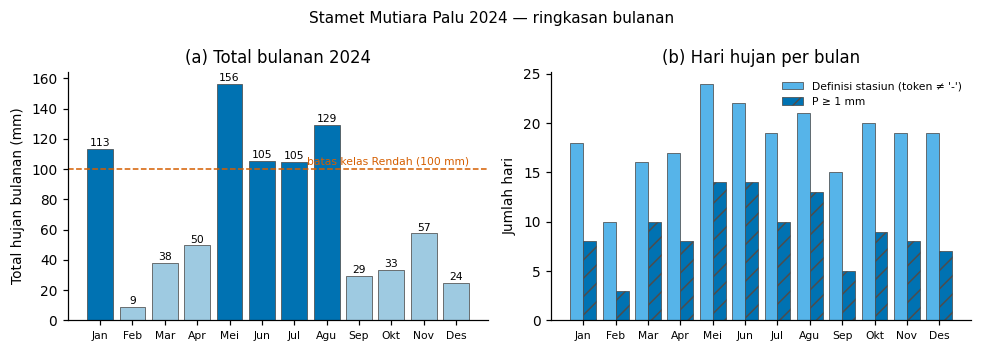

In [10]:
thr = CONFIG["wet_day_mm"]
o = obs.assign(is_dash=obs.raw_token.eq("-"), is_trace=obs.raw_token.eq("0"),
               is_token_num=obs.token_class.eq("numeric"), is_wet=obs.rain_mm.ge(thr),
               is_missing=obs.rain_mm.isna(), wet_rain=obs.rain_mm.where(obs.rain_mm.ge(thr), 0.0))
SEASON = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM", 6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
o["season"] = o.month.map(SEASON)

def summarize(group_key):
    t = o.groupby(group_key).agg(n_days=("rain_mm", "size"), n_missing=("is_missing", "sum"), n_dash=("is_dash", "sum"),
            n_trace=("is_trace", "sum"), hari_hujan_stasiun=("is_token_num", "sum"), hari_hujan_ge1mm=("is_wet", "sum"),
            total_mm=("rain_mm", "sum"), max_mm=("rain_mm", "max"), wet_sum=("wet_rain", "sum"))
    t["missing_fraction"] = t.n_missing / t.n_days
    t["mean_mm_per_day"] = t.total_mm / t.n_days
    t["SDII_mm"] = t.wet_sum / t.hari_hujan_ge1mm.replace(0, np.nan)
    return t.drop(columns="wet_sum")

monthly = summarize("month"); monthly.insert(0, "bulan", ID_MON)
monthly["kelas_bmkg"] = monthly.total_mm.map(bmkg_monthly_class)
seasonal = summarize("season").loc[["DJF", "MAM", "JJA", "SON"]]
display(monthly.round(2)); display(seasonal.round(2))
check("ANA-001: total tahunan = jumlah bulanan", abs(monthly.total_mm.sum() - o.rain_mm.sum()) < 1e-9, round(monthly.total_mm.sum(), 1))
check("ANA-001: total musiman = total tahunan", abs(seasonal.total_mm.sum() - monthly.total_mm.sum()) < 1e-9)
monthly.to_csv(OUT / "analysis" / "monthly-summary.csv", index=False)
seasonal.to_csv(OUT / "analysis" / "seasonal-summary.csv")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
cols = ["#0072B2" if v >= 100 else "#9ecae1" for v in monthly.total_mm]
ax[0].bar(monthly.bulan, monthly.total_mm, color=cols, edgecolor="0.3", linewidth=0.5)
ax[0].axhline(100, color="#D55E00", ls="--", lw=1); ax[0].text(11.4, 103, "batas kelas Rendah (100 mm)", ha="right", fontsize=7, color="#D55E00")
for x, v in enumerate(monthly.total_mm): ax[0].text(x, v + 2, f"{v:.0f}", ha="center", fontsize=7)
ax[0].set_ylabel("Total hujan bulanan (mm)"); ax[0].set_title("(a) Total bulanan 2024")
w = 0.4; xs = np.arange(12)
ax[1].bar(xs - w/2, monthly.hari_hujan_stasiun, w, color="#56B4E9", label="Definisi stasiun (token ≠ '-')", edgecolor="0.3", linewidth=0.5)
ax[1].bar(xs + w/2, monthly.hari_hujan_ge1mm, w, color="#0072B2", hatch="//", label="P ≥ 1 mm", edgecolor="0.3", linewidth=0.5)
ax[1].set_xticks(xs); ax[1].set_xticklabels(monthly.bulan); ax[1].set_ylabel("Jumlah hari"); ax[1].set_title("(b) Hari hujan per bulan"); ax[1].legend(fontsize=7, frameon=False)
for a in ax: a.tick_params(axis="x", labelsize=7)
fig.suptitle("Stamet Mutiara Palu 2024 — ringkasan bulanan", fontsize=10); fig.tight_layout()
fig.savefig(OUT / "figures" / "r-ana-001-monthly.png"); plt.show()

## 8. R-CAL-002 — Anomali terhadap baseline

$x'_t = x_t - \bar{x}_b$. Arti anomali **sepenuhnya ditentukan oleh baseline**, jadi baseline dicatat: periode, pengelompokan, dan jumlah sampel.

**Keterbatasan penting:** file ini hanya berisi satu tahun, sehingga **normal klimatologi (mis. 1991–2020) tidak tersedia**. Baseline default di sini adalah *rata-rata 12 bulan pada 2024 itu sendiri*. Itu menunjukkan bulan mana yang relatif basah/kering **di dalam tahun 2024**, bukan anomali klimatologis. Jika normal bulanan tersedia, isi `CONFIG["normals_mm"]` dan seluruh sel ini otomatis memakainya.

{'baseline_type': 'rata-rata bulanan dalam tahun yang sama (BUKAN klimatologi)', 'period': '2024', 'n_samples': 12}


,bulan,total_mm,baseline_mm,anomali_mm,anomali_persen
0,Jan,113.2,70.8,42.4,59.9
1,Feb,9.0,70.8,-61.8,-87.3
2,Mar,37.8,70.8,-33.0,-46.6
3,Apr,49.5,70.8,-21.3,-30.1
4,Mei,156.5,70.8,85.7,121.1
5,Jun,105.3,70.8,34.5,48.8
6,Jul,104.7,70.8,33.9,47.9
7,Agu,129.0,70.8,58.2,82.2
8,Sep,29.3,70.8,-41.5,-58.6
9,Okt,33.2,70.8,-37.6,-53.1


[LULUS] CAL-002: jumlah anomali terhadap baseline within-year = 0


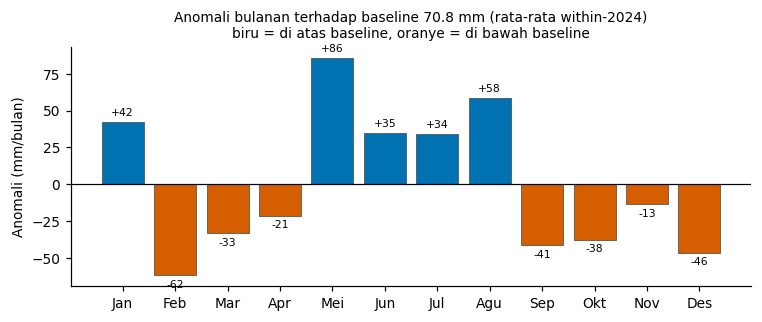

In [11]:
def monthly_anomaly(monthly_totals, normals=None):
    """Anomali = total bulanan - baseline. Mengembalikan (tabel, metadata baseline)."""
    t = pd.DataFrame({"bulan": ID_MON, "total_mm": monthly_totals.values})
    if normals is None:
        t["baseline_mm"] = t.total_mm.mean()
        meta = {"baseline_type": "rata-rata bulanan dalam tahun yang sama (BUKAN klimatologi)", "period": str(YEAR), "n_samples": len(t)}
    else:
        t["baseline_mm"] = [normals[m] for m in range(1, 13)]
        meta = {"baseline_type": "normal klimatologi dari pengguna", "period": "sesuai input", "n_samples": "sesuai input"}
    t["anomali_mm"] = t.total_mm - t.baseline_mm
    t["anomali_persen"] = 100 * t.anomali_mm / t.baseline_mm
    return t, meta

anom, anom_meta = monthly_anomaly(monthly.total_mm, CONFIG["normals_mm"])
print(anom_meta); display(anom.round(1))
if CONFIG["normals_mm"] is None:
    check("CAL-002: jumlah anomali terhadap baseline within-year = 0", abs(anom.anomali_mm.sum()) < 1e-9)
anom.to_csv(OUT / "calc" / "monthly-anomaly.csv", index=False); save_json(anom_meta, OUT / "calc" / "monthly-anomaly-baseline.json")

fig, ax = plt.subplots(figsize=(7, 3))
bar_colors = ["#0072B2" if v >= 0 else "#D55E00" for v in anom.anomali_mm]
ax.bar(anom.bulan, anom.anomali_mm, color=bar_colors, edgecolor="0.3", linewidth=0.5)
ax.axhline(0, color="k", lw=0.8)
for x, v in enumerate(anom.anomali_mm): ax.text(x, v + (3 if v >= 0 else -3), f"{v:+.0f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=7)
ax.set_ylabel("Anomali (mm/bulan)"); ax.set_title(f"Anomali bulanan terhadap baseline {anom.baseline_mm[0]:.1f} mm (rata-rata within-{YEAR})\nbiru = di atas baseline, oranye = di bawah baseline", fontsize=9)
fig.tight_layout(); fig.savefig(OUT / "figures" / "r-cal-002-anomaly.png"); plt.show()

## 9. R-CAL-003 — Lag correlation (autokorelasi hujan harian)

**Konvensi tanda (wajib dinyatakan):** $r(L)=\mathrm{corr}(x_t,\,y_{t+L})$. Lag **positif** berarti $y$ *mengikuti* $x$ sebesar $L$ hari. Hanya *valid pair* yang dipakai; minimum 30 pasangan.

Data ini hanya punya satu variabel, jadi yang bisa dihitung adalah **autokorelasi** ($y=x$): apakah hari basah cenderung diikuti hari basah? Untuk korelasi-silang sungguhan diperlukan variabel kedua (debit, SST, indeks ENSO/IOD, dsb.) — lihat langkah lanjut di akhir.

Fungsi diverifikasi dulu pada data buatan dengan lag yang diketahui (3 hari). Dua metrik dilaporkan: Pearson (sensitif terhadap ekstrem seperti 50,5 mm) dan Spearman (berbasis peringkat, lebih robust). Garis ±1,96/√n hanyalah pembatas kasar untuk white-noise; mencoba banyak lag meningkatkan peluang puncak palsu, jadi jangan dibaca sebagai uji signifikansi formal.

[LULUS] CAL-003: fixture y_t=x_(t-3) -> puncak pada lag +3 (y mengikuti x) — lag=3, r=1.000


,lag_days,n_pairs,r_pearson,r_spearman,approx_bound
0,0,366,1.000,1.000,0.102
1,1,365,0.089,0.208,0.103
2,2,364,0.068,0.101,0.103
3,3,363,0.076,0.144,0.103
4,4,362,0.034,0.113,0.103
5,5,361,-0.017,0.099,0.103
6,6,360,0.055,0.086,0.103
7,7,359,-0.016,0.043,0.103
8,8,358,0.039,0.060,0.104
9,9,357,-0.030,0.060,0.104


[LULUS] CAL-003: lag 0 = 1 (identitas)


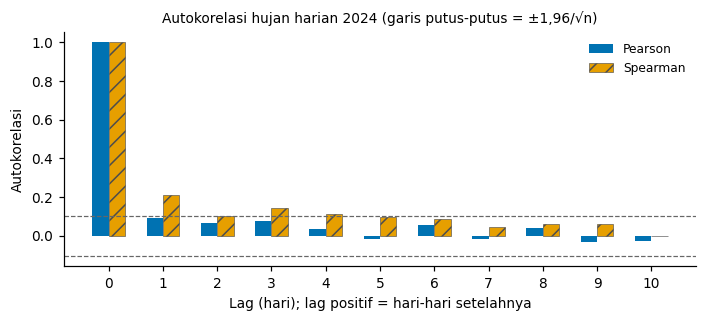

In [12]:
def lag_correlation(x, y, lags, min_pairs=30):
    """r(L) = corr(x_t, y_{t+L}); L>0: y mengikuti x. Hanya valid pair. Pearson & Spearman."""
    x = pd.Series(np.asarray(x, float)); y = pd.Series(np.asarray(y, float)); rows = []
    for L in lags:
        pair = pd.concat([x, y.shift(-L)], axis=1).dropna()
        n = len(pair)
        ok = n >= min_pairs
        rows.append({"lag_days": L, "n_pairs": n,
                     "r_pearson": pair.corr().iloc[0, 1] if ok else np.nan,
                     "r_spearman": pair.corr(method="spearman").iloc[0, 1] if ok else np.nan,
                     "approx_bound": 1.96 / np.sqrt(n) if n else np.nan})
    return pd.DataFrame(rows)

# verifikasi: y_t = x_{t-3}  =>  puncak r pada L = +3
rng = np.random.default_rng(42); a = rng.normal(size=300); b = np.roll(a, 3)
lc_fx = lag_correlation(a, b, range(-6, 7))
peak_L = int(lc_fx.loc[lc_fx.r_pearson.idxmax(), "lag_days"])
check("CAL-003: fixture y_t=x_(t-3) -> puncak pada lag +3 (y mengikuti x)", peak_L == 3 and lc_fx.r_pearson.max() > 0.99, f"lag={peak_L}, r={lc_fx.r_pearson.max():.3f}")

rain = obs.rain_mm.to_numpy()
ac = lag_correlation(rain, rain, range(0, 11))
display(ac.round(3))
check("CAL-003: lag 0 = 1 (identitas)", abs(ac.r_pearson[0] - 1) < 1e-12 and abs(ac.r_spearman[0] - 1) < 1e-12)
ac.to_csv(OUT / "calc" / "autocorrelation-daily-rain.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.bar(ac.lag_days - 0.15, ac.r_pearson, 0.3, color="#0072B2", label="Pearson")
ax.bar(ac.lag_days + 0.15, ac.r_spearman, 0.3, color="#E69F00", hatch="//", edgecolor="0.3", linewidth=0.4, label="Spearman")
ax.axhline(ac.approx_bound[1], color="0.4", ls="--", lw=0.8); ax.axhline(-ac.approx_bound[1], color="0.4", ls="--", lw=0.8)
ax.set_xlabel("Lag (hari); lag positif = hari-hari setelahnya"); ax.set_ylabel("Autokorelasi"); ax.set_xticks(ac.lag_days)
ax.set_title("Autokorelasi hujan harian 2024 (garis putus-putus = ±1,96/√n)", fontsize=9); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "figures" / "r-cal-003-autocorr.png"); plt.show()

## 10. R-VIS-001 — Figure time-series yang informatif

Fungsi plotting yang dapat dipakai ulang: unit pada sumbu, **interval missing diarsir tanpa menyambung gap**, token `0` (jejak) ditandai terpisah dari hari tanpa hujan, tiga kejadian terbesar dilabeli, dan panel kedua menunjukkan akumulasi. Data tidak diubah. Disimpan sebagai PNG eksploratori dan PDF (kandidat publikasi).

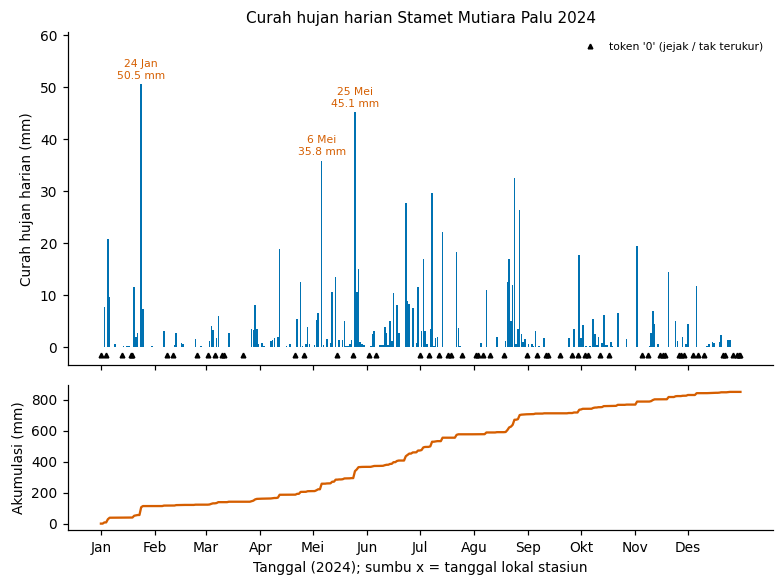

In [13]:
def plot_daily_series(dates, values, trace_mask=None, top_n=3, title="", out_png=None, out_pdf=None):
    dates = pd.DatetimeIndex(dates); v = np.asarray(values, float)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(7.2, 5.4), sharex=True, gridspec_kw={"height_ratios": [2.3, 1]})
    a1.bar(dates, np.nan_to_num(v), width=0.9, color="#0072B2")
    miss = np.isnan(v)                                  # interval missing: arsir, jangan disambung
    if miss.any():
        for s, e in zip(*[np.where(d)[0] for d in (np.diff(np.r_[0, miss.astype(int)]) == 1, np.diff(np.r_[miss.astype(int), 0]) == -1)]):
            a1.axvspan(dates[s] - pd.Timedelta(hours=12), dates[e] + pd.Timedelta(hours=12), color="0.8", hatch="//", alpha=0.6)
    if trace_mask is not None and np.any(trace_mask):
        a1.plot(dates[trace_mask], np.full(int(np.sum(trace_mask)), -1.6), ls="none", marker="^", ms=3, color="k", label="token '0' (jejak / tak terukur)")
    for i in np.argsort(-np.nan_to_num(v))[:top_n]:
        a1.annotate(f"{dates[i].day} {ID_MON[dates[i].month-1]}\n{v[i]:.1f} mm", (dates[i], v[i]), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=7, color="#D55E00")
    a1.set_ylim(-3.5, np.nanmax(v) * 1.2); a1.set_ylabel("Curah hujan harian (mm)"); a1.legend(loc="upper right", frameon=False, fontsize=7)
    a1.set_title(title, fontsize=10)
    a2.plot(dates, np.nancumsum(v), color="#D55E00", lw=1.5); a2.set_ylabel("Akumulasi (mm)")
    ms = pd.date_range(dates.min().replace(day=1), dates.max(), freq="MS")
    a2.set_xticks(ms); a2.set_xticklabels([ID_MON[d.month - 1] for d in ms]); a2.set_xlabel(f"Tanggal ({dates.min().year}); sumbu x = tanggal lokal stasiun")
    fig.tight_layout()
    if out_png: fig.savefig(out_png)
    if out_pdf: fig.savefig(out_pdf)
    return fig

fig = plot_daily_series(obs.date, obs.rain_mm.where(~obs.rain_mm.isna()), trace_mask=obs.raw_token.eq("0").to_numpy(),
                        title=f"Curah hujan harian Stamet Mutiara Palu {YEAR}",
                        out_png=OUT / "figures" / "r-vis-001-daily.png", out_pdf=OUT / "figures" / "r-vis-001-daily.pdf")
plt.show()

## 11. R-CS-002 + R-MOD-003 — Linear reservoir rainfall–runoff dengan forcing hujan nyata

**Teori minimal** (Bab 24 buku): neraca storage $\dfrac{dS}{dt}=P-E-Q$. Untuk reservoir linear $Q=S/k$ dan $P$ konstan dalam satu langkah harian, solusi eksak:
$S_{n+1}=S_n e^{-\Delta t/k}+kP_{\mathrm{eff}}(1-e^{-\Delta t/k})$, dan debit rata-rata langkah dihitung dari neraca massa $Q_n=(S_n+P_{\mathrm{eff}}\Delta t-S_{n+1})/\Delta t$, sehingga massa kekal **secara konstruksi**. Evapotranspirasi disederhanakan sebagai kehilangan konstan $E$: $P_{\mathrm{eff}}=\max(P-E,0)$.

**Batas evidence (jujur):** buku menjalankan recipe ini pada forcing *sintetis*. Di sini forcing-nya hujan nyata Palu, tetapi **tidak ada debit teramati, luas DAS, maupun ET terukur**. Karena itu: $k$ dan $E$ adalah *skenario*, luas DAS 12,5 km² adalah *asumsi ilustratif* dari fixture buku, dan hasilnya **bukan kalibrasi, validasi, maupun prakiraan banjir**. Experiment matrix (R-MOD-003) dipakai untuk melihat *sensitivitas* terhadap parameter, bukan memilih parameter "terbaik".

In [14]:
def linear_reservoir(p_mm_day, k_days, s0_mm=0.0, et_mm_day=0.0, dt_days=1.0):
    """Reservoir linear satu tampungan. P, E, Q: mm/hari (kedalaman setara DAS); S: mm.
    Solusi eksak per langkah (P_eff konstan); Q rata-rata langkah dari neraca massa."""
    p = np.asarray(p_mm_day, float)
    if k_days <= 0 or et_mm_day < 0 or s0_mm < 0 or np.any(p < 0) or np.any(~np.isfinite(p)):
        raise ValueError("parameter/forcing di luar domain")
    p_eff = np.maximum(p - et_mm_day, 0.0)
    a = np.exp(-dt_days / k_days)
    s = np.empty(len(p) + 1); s[0] = s0_mm; q = np.empty(len(p))
    for i in range(len(p)):
        s[i + 1] = s[i] * a + k_days * p_eff[i] * (1 - a)
        q[i] = (s[i] + p_eff[i] * dt_days - s[i + 1]) / dt_days
    return {"S": s, "Q": q, "P_eff": p_eff, "loss": p - p_eff}

# ---- verifikasi terhadap solusi analitik --------------------------------------------------
r = linear_reservoir(np.zeros(10), k_days=2.5, s0_mm=10.0)
check("CS-002: resesi bebas S_n = S0*exp(-n/k) (tol 1e-12)", np.allclose(r["S"], 10 * np.exp(-np.arange(11) / 2.5), atol=1e-12))
r = linear_reservoir(np.full(200, 5.0), k_days=5.0)
check("CS-002: P konstan -> steady state S=kP, Q=P (tol 1e-9)", abs(r["S"][-1] - 25.0) < 1e-9 and abs(r["Q"][-1] - 5.0) < 1e-9)
check("CS-002: Q tidak pernah negatif", (r["Q"] >= 0).all())
try: linear_reservoir([1.0], k_days=0); ok = False
except ValueError: ok = True
check("CS-002: k <= 0 ditolak", ok)

# ---- experiment matrix --------------------------------------------------------------------
P = obs.rain_mm.to_numpy(); dates = obs.date.to_numpy()
rows, runs = [], {}
for k, e in itertools.product(CONFIG["reservoir_k_days"], CONFIG["reservoir_et_mm_day"]):
    res = linear_reservoir(P, k, 0.0, e); runs[(k, e)] = res
    resid = P.sum() - res["loss"].sum() - (res["S"][-1] - res["S"][0]) - res["Q"].sum()
    ip = int(np.argmax(res["Q"]))
    rows.append({"k_hari": k, "ET_mm_hari": e, "Q_puncak_mm_hari": res["Q"][ip],
                 "Q_puncak_m3s_asumsi_A": float(depth_mm_day_to_discharge_m3s(res["Q"][ip], CONFIG["catchment_area_km2"])),
                 "tanggal_puncak": pd.Timestamp(dates[ip]).date(), "Q_total_mm": res["Q"].sum(), "loss_mm": res["loss"].sum(),
                 "S_akhir_mm": res["S"][-1], "runoff_ratio": res["Q"].sum() / P.sum(), "residual_neraca_mm": resid})
matrix = pd.DataFrame(rows)
display(matrix.round(3))
check("CS-002: residual neraca massa semua skenario < 1e-9 mm", matrix.residual_neraca_mm.abs().max() < 1e-9, f"maks={matrix.residual_neraca_mm.abs().max():.2e}")
matrix.to_csv(OUT / "model" / "experiment-matrix.csv", index=False)
save_json({"forcing": "hujan harian Stamet Mutiara Palu 2024 (rain_mm)", "k_days": CONFIG["reservoir_k_days"], "et_mm_day": CONFIG["reservoir_et_mm_day"],
           "catchment_area_km2_ASSUMED": CONFIG["catchment_area_km2"], "s0_mm": 0.0, "status": "skenario ilustratif; tanpa kalibrasi/validasi"},
          OUT / "model" / "experiment-config.json")

[LULUS] CS-002: resesi bebas S_n = S0*exp(-n/k) (tol 1e-12)
[LULUS] CS-002: P konstan -> steady state S=kP, Q=P (tol 1e-9)
[LULUS] CS-002: Q tidak pernah negatif
[LULUS] CS-002: k <= 0 ditolak


,k_hari,ET_mm_hari,Q_puncak_mm_hari,Q_puncak_m3s_asumsi_A,tanggal_puncak,Q_total_mm,loss_mm,S_akhir_mm,runoff_ratio,residual_neraca_mm
0,1.0,0.0,23.097,3.342,2024-01-25,849.397,0.0,0.003,1.000,-0.0
1,1.0,3.0,20.587,2.978,2024-01-25,554.900,294.5,0.000,0.653,-0.0
2,2.5,0.0,16.124,2.333,2024-01-25,849.205,0.0,0.195,1.000,0.0
3,2.5,3.0,14.116,2.042,2024-01-25,554.900,294.5,0.000,0.653,-0.0
4,5.0,0.0,10.656,1.542,2024-08-28,848.271,0.0,1.129,0.999,0.0
5,5.0,3.0,8.931,1.292,2024-01-25,554.839,294.5,0.061,0.653,-0.0
6,10.0,0.0,7.791,1.127,2024-08-28,844.901,0.0,4.499,0.995,0.0
7,10.0,3.0,6.108,0.884,2024-08-28,553.837,294.5,1.063,0.652,0.0


[LULUS] CS-002: residual neraca massa semua skenario < 1e-9 mm — maks=1.14e-13


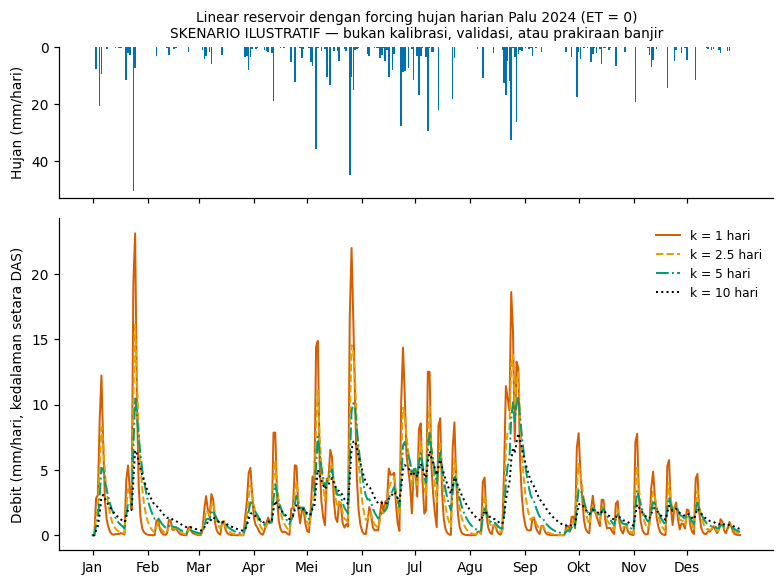

In [15]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7.2, 5.4), sharex=True, gridspec_kw={"height_ratios": [1, 2.2]})
a1.bar(obs.date, P, width=0.9, color="#0072B2"); a1.invert_yaxis(); a1.set_ylabel("Hujan (mm/hari)")
a1.set_title("Linear reservoir dengan forcing hujan harian Palu 2024 (ET = 0)\nSKENARIO ILUSTRATIF — bukan kalibrasi, validasi, atau prakiraan banjir", fontsize=9)
styles = {1.0: ("#D55E00", "-"), 2.5: ("#E69F00", "--"), 5.0: ("#009E73", "-."), 10.0: ("#000000", ":")}
for k in CONFIG["reservoir_k_days"]:
    c, ls = styles.get(k, ("0.3", "-")); a2.plot(obs.date, runs[(k, 0.0)]["Q"], color=c, ls=ls, lw=1.3, label=f"k = {k:g} hari")
a2.set_ylabel("Debit (mm/hari, kedalaman setara DAS)"); a2.legend(frameon=False, fontsize=8)
ms = pd.date_range(f"{YEAR}-01-01", f"{YEAR}-12-01", freq="MS"); a2.set_xticks(ms); a2.set_xticklabels([ID_MON[d.month - 1] for d in ms])
fig.tight_layout(); fig.savefig(OUT / "figures" / "r-cs-002-hydrograph.png"); plt.show()

## 12. R-HPC-001 — Ukur dulu sebelum mengoptimasi

Aturan buku: jangan ubah kode sebelum pengukuran menunjukkan bottleneck. Di sini diukur (a) rolling-sum dengan loop Python vs NumPy (dipakai untuk Rx5day di recipe saya) dan (b) satu run reservoir. Pada data 366 baris, pertanyaannya sederhana: apakah ada yang perlu dioptimasi?

In [16]:
def rolling_sum_loop(x, w):  return np.array([sum(x[i:i + w]) for i in range(len(x) - w + 1)])
def rolling_sum_numpy(x, w): c = np.cumsum(np.insert(np.asarray(x, float), 0, 0.0)); return c[w:] - c[:-w]

x = obs.rain_mm.to_numpy(float)
t_loop = timeit.timeit(lambda: rolling_sum_loop(x, 5), number=200) / 200
t_np   = timeit.timeit(lambda: rolling_sum_numpy(x, 5), number=200) / 200
t_res  = timeit.timeit(lambda: linear_reservoir(x, 2.5), number=200) / 200
diff = float(np.max(np.abs(rolling_sum_loop(x, 5) - rolling_sum_numpy(x, 5))))
print(f"rolling 5-hari, loop Python : {t_loop*1e3:.4f} ms/panggilan")
print(f"rolling 5-hari, NumPy       : {t_np*1e3:.4f} ms/panggilan  (percepatan ~{t_loop/t_np:.1f}x)")
print(f"satu run linear reservoir   : {t_res*1e3:.4f} ms/panggilan")
print(f"selisih maksimum loop vs NumPy: {diff:.2e}")
check("HPC-001: loop dan NumPy ekuivalen (tol 1e-9)", diff < 1e-9)
save_json({"n_values": int(len(x)), "repeat": 200, "t_loop_s": t_loop, "t_numpy_s": t_np, "t_reservoir_s": t_res, "max_abs_diff": diff,
           "note": "waktu berlaku untuk mesin & workload ini saja"}, OUT / "calc" / "profile-summary.json")
print("\nKeputusan:", "tidak ada bottleneck; seluruh analisis selesai dalam milidetik, jadi TIDAK perlu optimasi/paralelisasi untuk 1 stasiun x 1 tahun."
      if t_res < 0.05 else "periksa profil lebih lanjut.")

rolling 5-hari, loop Python : 0.2736 ms/panggilan
rolling 5-hari, NumPy       : 0.0099 ms/panggilan  (percepatan ~27.8x)
satu run linear reservoir   : 0.1997 ms/panggilan
selisih maksimum loop vs NumPy: 1.36e-13
[LULUS] HPC-001: loop dan NumPy ekuivalen (tol 1e-9)

Keputusan: tidak ada bottleneck; seluruh analisis selesai dalam milidetik, jadi TIDAK perlu optimasi/paralelisasi untuk 1 stasiun x 1 tahun.


---
# 13. Recipe saya — `R-HJN-001`
## Indeks Hujan Ekstrem (ETCCDI) dan Spell Kering/Basah, dengan Verifikasi terhadap Ringkasan Stasiun

**Mengapa recipe ini?** Recipe di buku mencakup I/O, QC, ringkasan bulanan, anomali, dan model. Yang belum ada untuk data hujan stasiun: *karakterisasi ekstrem dan persistensi* (berapa hari kering beruntun terpanjang, seberapa besar kontribusi hujan ekstrem terhadap total) **dan** cara membuktikan bahwa hitungan itu benar. R-HJN-001 menambahkan keduanya, dengan struktur yang sama dengan recipe buku (Problem, AI role, stack, prompt, code, expected output, check, batas interpretasi).

### Definisi operasional (ETCCDI, ambang hari basah θ = 1 mm)

| Indeks | Definisi |
|---|---|
| PRCPTOT | total hujan pada hari basah (P ≥ θ) |
| R1mm / R10mm / R20mm / R50mm | jumlah hari dengan P ≥ 1 / 10 / 20 / 50 mm |
| SDII | PRCPTOT / jumlah hari basah |
| Rx1day, Rx5day | maksimum hujan 1 hari dan 5 hari berurutan |
| CDD, CWD | spell kering (P < θ) dan basah (P ≥ θ) beruntun terpanjang |
| R95p | total hujan hari basah yang melebihi persentil ke-95 hujan hari basah |

> **Catatan metodologis:** ETCCDI mendefinisikan R95p dengan persentil dari *periode dasar* 30 tahun (1961–1990). Dengan satu tahun data, persentil di sini dihitung **dalam tahun 2024 itu sendiri** (`percentile_basis = "within-year"`). Angka R95p karena itu tidak setara dengan R95p klimatologis.

### Prompt `P-HJN-001` (format Role–Task–Context–Input–Constraints–Output, sesuai R-META-002)

In [17]:
PROMPT_MD = """# P-HJN-001 — Indeks hujan ekstrem dan spell kering/basah

**Role.** Asisten analisis klimatologi data stasiun.

**Task.** Hitung indeks hujan ekstrem (PRCPTOT, R1mm, R10mm, R20mm, R50mm, SDII, Rx1day, Rx5day, CDD, CWD, R95p) dan tabel spell kering/basah dari [DATA_PATH], lalu verifikasi hasilnya.

**Context.** Data harian satu stasiun, tahun [YEAR]. Token [DRY_TOKEN] berarti tidak ada hujan dan token [TRACE_TOKEN] berarti jejak (konfirmasi bila belum pasti). Ambang hari basah [WET_DAY_MM] mm (default 1.0).

**Input.** [DATA_PATH]; baris ringkasan stasiun (jumlah, hari hujan, maksimum) bila tersedia sebagai pembanding independen.

**Constraints.**
- Jangan mengubah atau menghapus data sumber; catat setiap kebijakan transformasi.
- Nyatakan unit, konvensi waktu, dan basis persentil R95p.
- Jika ada missing value, hentikan dan minta kebijakan eksplisit; jangan menyambung spell melewati gap.
- Verifikasi minimal: (1) cocokkan dengan ringkasan stasiun, (2) invarian partisi spell, (3) implementasi vektor vs brute-force, (4) fixture dengan jawaban yang diketahui, (5) sensitivitas terhadap ambang.
- Jangan menyimpulkan tren, anomali klimatologis, atau penyebab fisis dari satu stasiun dan satu tahun.

**Output.** rain-indices.json, rain-spells-dry.csv, rain-spells-wet.csv, rain-indices-monthly.csv, rain-threshold-sensitivity.csv, satu figure ringkasan, dan laporan verifikasi (daftar check lulus/gagal) beserta batas interpretasi.
"""
(OUT / "recipes" / "p-hjn-001.md").write_text(PROMPT_MD, encoding="utf-8")
show_md(PROMPT_MD)

# P-HJN-001 — Indeks hujan ekstrem dan spell kering/basah

**Role.** Asisten analisis klimatologi data stasiun.

**Task.** Hitung indeks hujan ekstrem (PRCPTOT, R1mm, R10mm, R20mm, R50mm, SDII, Rx1day, Rx5day, CDD, CWD, R95p) dan tabel spell kering/basah dari [DATA_PATH], lalu verifikasi hasilnya.

**Context.** Data harian satu stasiun, tahun [YEAR]. Token [DRY_TOKEN] berarti tidak ada hujan dan token [TRACE_TOKEN] berarti jejak (konfirmasi bila belum pasti). Ambang hari basah [WET_DAY_MM] mm (default 1.0).

**Input.** [DATA_PATH]; baris ringkasan stasiun (jumlah, hari hujan, maksimum) bila tersedia sebagai pembanding independen.

**Constraints.**
- Jangan mengubah atau menghapus data sumber; catat setiap kebijakan transformasi.
- Nyatakan unit, konvensi waktu, dan basis persentil R95p.
- Jika ada missing value, hentikan dan minta kebijakan eksplisit; jangan menyambung spell melewati gap.
- Verifikasi minimal: (1) cocokkan dengan ringkasan stasiun, (2) invarian partisi spell, (3) implementasi vektor vs brute-force, (4) fixture dengan jawaban yang diketahui, (5) sensitivitas terhadap ambang.
- Jangan menyimpulkan tren, anomali klimatologis, atau penyebab fisis dari satu stasiun dan satu tahun.

**Output.** rain-indices.json, rain-spells-dry.csv, rain-spells-wet.csv, rain-indices-monthly.csv, rain-threshold-sensitivity.csv, satu figure ringkasan, dan laporan verifikasi (daftar check lulus/gagal) beserta batas interpretasi.


### Implementasi
Dua implementasi dibuat sengaja: versi **vektor** (dipakai) dan versi **brute-force** `itertools.groupby` (pembanding verifikasi).

In [18]:
def find_spells(flag):
    """Indeks (start, end) setiap run True pada array boolean (vektor)."""
    f = np.asarray(flag, bool).astype(np.int8)
    d = np.diff(np.concatenate(([0], f, [0])))
    return np.where(d == 1)[0], np.where(d == -1)[0] - 1

def find_spells_bruteforce(flag):
    """Pembanding: run True via itertools.groupby."""
    out, pos = [], 0
    for val, grp in itertools.groupby(flag):
        n = len(list(grp))
        if val: out.append((pos, pos + n - 1))
        pos += n
    return out

def spell_table(dates, rain, flag):
    s, e = find_spells(flag); rows = []
    for i, (a, b) in enumerate(zip(s, e), start=1):
        seg = rain[a:b + 1]
        rows.append({"spell_id": i, "start": dates[a], "end": dates[b], "duration_days": int(b - a + 1),
                     "total_mm": float(seg.sum()), "peak_mm": float(seg.max())})
    return pd.DataFrame(rows, columns=["spell_id", "start", "end", "duration_days", "total_mm", "peak_mm"])

def compute_rain_indices(dates, rain, wet_thr=1.0):
    """Indeks ekstrem ETCCDI + tabel spell. rain: mm/hari tanpa NaN (NaN -> ValueError: tentukan kebijakan missing dulu)."""
    dates = pd.DatetimeIndex(dates); rain = np.asarray(rain, float)
    if np.isnan(rain).any(): raise ValueError("ada NaN: tentukan kebijakan missing eksplisit sebelum menghitung spell")
    if (rain < 0).any(): raise ValueError("nilai negatif")
    wet = rain >= wet_thr
    dry_tbl = spell_table(dates, rain, ~wet); wet_tbl = spell_table(dates, rain, wet)
    r5 = rolling_sum_numpy(rain, 5); i5 = int(np.argmax(r5)); i1 = int(np.argmax(rain))
    cdd = dry_tbl.loc[dry_tbl.duration_days.idxmax()] if len(dry_tbl) else None
    cwd = wet_tbl.loc[wet_tbl.duration_days.idxmax()] if len(wet_tbl) else None
    wet_vals = rain[wet]; p95 = float(np.percentile(wet_vals, 95)) if wet_vals.size else np.nan
    idx = {
        "wet_day_threshold_mm": wet_thr, "n_days": int(len(rain)), "annual_total_mm": float(rain.sum()),
        "PRCPTOT_mm": float(wet_vals.sum()), "R1mm_days": int(wet.sum()), "R10mm_days": int((rain >= 10).sum()),
        "R20mm_days": int((rain >= 20).sum()), "R50mm_days": int((rain >= 50).sum()),
        "SDII_mm_per_wet_day": float(wet_vals.mean()) if wet_vals.size else np.nan,
        "Rx1day_mm": float(rain[i1]), "Rx1day_date": dates[i1],
        "Rx5day_mm": float(r5[i5]), "Rx5day_start": dates[i5], "Rx5day_end": dates[i5 + 4],
        "CDD_days": int(cdd.duration_days) if cdd is not None else 0, "CDD_start": cdd.start if cdd is not None else None, "CDD_end": cdd.end if cdd is not None else None,
        "CWD_days": int(cwd.duration_days) if cwd is not None else 0, "CWD_start": cwd.start if cwd is not None else None, "CWD_end": cwd.end if cwd is not None else None,
        "p95_wet_mm": p95, "R95p_mm": float(wet_vals[wet_vals > p95].sum()) if wet_vals.size else 0.0,
        "percentile_basis": "within-year (BUKAN periode dasar 30 tahun ETCCDI)",
        "n_dry_spells": int(len(dry_tbl)), "n_wet_spells": int(len(wet_tbl)), "n_dry_spells_ge7d": int((dry_tbl.duration_days >= 7).sum()),
    }
    idx["R95p_fraction_of_PRCPTOT"] = idx["R95p_mm"] / idx["PRCPTOT_mm"] if idx["PRCPTOT_mm"] else np.nan
    return idx, dry_tbl, wet_tbl

# ---- V5 lebih dulu: fixture dengan jawaban yang dihitung tangan ----------------------------
fx_rain = np.array([0, 0, 2, 3, 0, 0, 0, 5, 6, 7, 0], float); fx_dates = pd.date_range("2024-01-01", periods=len(fx_rain))
fx_idx, fx_dry, fx_wet = compute_rain_indices(fx_dates, fx_rain, 1.0)
expected = {"PRCPTOT_mm": 23.0, "R1mm_days": 5, "SDII_mm_per_wet_day": 4.6, "Rx1day_mm": 7.0, "Rx5day_mm": 18.0, "CDD_days": 3, "CWD_days": 3, "R10mm_days": 0}
for k, v in expected.items():
    check(f"V5 fixture: {k} = {v}", abs(fx_idx[k] - v) < 1e-9, fx_idx[k])
check("V5 fixture: wet spell [2 hari/5 mm, 3 hari/18 mm]", fx_wet.duration_days.tolist() == [2, 3] and fx_wet.total_mm.tolist() == [5.0, 18.0])

[LULUS] V5 fixture: PRCPTOT_mm = 23.0 — 23.0
[LULUS] V5 fixture: R1mm_days = 5 — 5
[LULUS] V5 fixture: SDII_mm_per_wet_day = 4.6 — 4.6
[LULUS] V5 fixture: Rx1day_mm = 7.0 — 7.0
[LULUS] V5 fixture: Rx5day_mm = 18.0 — 18.0
[LULUS] V5 fixture: CDD_days = 3 — 3
[LULUS] V5 fixture: CWD_days = 3 — 3
[LULUS] V5 fixture: R10mm_days = 0
[LULUS] V5 fixture: wet spell [2 hari/5 mm, 3 hari/18 mm]


### Jalankan pada data Palu 2024

In [19]:
idx, dry_tbl, wet_tbl = compute_rain_indices(obs.date, obs.rain_mm, CONFIG["wet_day_mm"])
idx_show = pd.Series({k: (v.date().isoformat() if isinstance(v, pd.Timestamp) else v) for k, v in idx.items()}, name="nilai").to_frame()
display(idx_show)
print("\nSpell kering terpanjang (5 teratas):"); display(dry_tbl.sort_values("duration_days", ascending=False).head(5).round({"total_mm": 1, "peak_mm": 1}))
print("Spell basah terpanjang (5 teratas):");  display(wet_tbl.sort_values("duration_days", ascending=False).head(5).round({"total_mm": 1, "peak_mm": 1}))

,nilai
wet_day_threshold_mm,1.0
n_days,366
annual_total_mm,849.4
PRCPTOT_mm,829.0
R1mm_days,109
R10mm_days,28
R20mm_days,9
R50mm_days,1
SDII_mm_per_wet_day,7.605505
Rx1day_mm,50.5



Spell kering terpanjang (5 teratas):


,spell_id,start,end,duration_days,total_mm,peak_mm
37,38,2024-07-24,2024-08-07,15,0.8,0.7
43,44,2024-09-11,2024-09-23,13,0.0,0.0
2,3,2024-01-07,2024-01-19,13,1.2,0.6
10,11,2024-03-15,2024-03-26,12,0.0,0.0
4,5,2024-01-26,2024-02-05,11,0.1,0.1


Spell basah terpanjang (5 teratas):


,spell_id,start,end,duration_days,total_mm,peak_mm
39,40,2024-08-19,2024-08-24,6,79.9,32.5
40,41,2024-08-26,2024-08-30,5,34.9,26.4
10,11,2024-03-27,2024-03-30,4,18.3,8.0
24,25,2024-05-25,2024-05-28,4,71.6,45.1
7,8,2024-03-03,2024-03-05,3,8.5,4.1


### Verifikasi V1–V6 (bagian terpenting recipe ini)

| ID | Pertanyaan | Jenis |
|---|---|---|
| V1 | Apakah hitungan ulang cocok dengan ringkasan stasiun (JUMLAH, max)? | pembanding independen |
| V2 | Apakah spell kering + basah menutup tepat seluruh hari (tanpa tumpang-tindih)? | invarian |
| V3 | Apakah massa hujan terpartisi dengan benar (Σ spell basah = PRCPTOT; + spell kering = total tahunan)? | konservasi |
| V4 | Apakah implementasi vektor = brute-force (`groupby`) dan rolling NumPy = loop? | dua implementasi |
| V5 | Fixture dengan jawaban hitung-tangan | analytic reference (sel sebelumnya) |
| V6 | Seberapa sensitif hasil terhadap ambang hari basah dan kebijakan token? | sensitivitas |

In [20]:
rain_arr = obs.rain_mm.to_numpy(float)
# V1
check("V1: Σ JUMLAH stasiun = total tahunan hitungan", abs(np.nansum(st_sum) - idx["annual_total_mm"]) < 0.05, f"{np.nansum(st_sum):.1f} vs {idx['annual_total_mm']:.1f}")
check("V1: Rx1day = maksimum baris 'max' stasiun", abs(np.nanmax(st_max) - idx["Rx1day_mm"]) < 1e-9, idx["Rx1day_mm"])
# V2
total_len = int(dry_tbl.duration_days.sum() + wet_tbl.duration_days.sum())
check("V2: Σ durasi spell kering + basah = jumlah hari", total_len == len(obs), f"{total_len} = {len(obs)}")
s_d, e_d = find_spells(rain_arr < CONFIG["wet_day_mm"]); s_w, e_w = find_spells(rain_arr >= CONFIG["wet_day_mm"])
cover = np.zeros(len(obs), int)
for a, b in list(zip(s_d, e_d)) + list(zip(s_w, e_w)): cover[a:b + 1] += 1
check("V2: setiap hari tercakup tepat satu spell", (cover == 1).all())
# V3
check("V3: Σ total_mm spell basah = PRCPTOT", abs(wet_tbl.total_mm.sum() - idx["PRCPTOT_mm"]) < 1e-9)
check("V3: PRCPTOT + Σ total_mm spell kering = total tahunan", abs(idx["PRCPTOT_mm"] + dry_tbl.total_mm.sum() - idx["annual_total_mm"]) < 1e-9)
# V4
wet_flag = rain_arr >= CONFIG["wet_day_mm"]
check("V4: spell vektor = brute-force (kering)", list(zip(*find_spells(~wet_flag))) == find_spells_bruteforce(list(~wet_flag)))
check("V4: spell vektor = brute-force (basah)",  list(zip(*find_spells(wet_flag)))  == find_spells_bruteforce(list(wet_flag)))
check("V4: Rx5day dari NumPy = dari loop", abs(rolling_sum_loop(rain_arr, 5).max() - idx["Rx5day_mm"]) < 1e-9)
# V6 sensitivitas
rows = []
for th in CONFIG["dry_wet_sensitivity_mm"]:
    i, d, w = compute_rain_indices(obs.date, obs.rain_mm, th)
    rows.append({"ambang_mm": th, "hari_basah": i["R1mm_days"], "PRCPTOT_mm": i["PRCPTOT_mm"], "SDII": i["SDII_mm_per_wet_day"], "CDD_hari": i["CDD_days"], "CWD_hari": i["CWD_days"], "n_spell_kering": i["n_dry_spells"]})
sens = pd.DataFrame(rows); display(sens.round(2))
tok = int(obs.raw_token.ne("-").sum())
print(f"\nKebijakan token: hari hujan versi stasiun (token ≠ '-') = {tok} hari vs R1mm = {idx['R1mm_days']} hari → selisih {tok - idx['R1mm_days']} hari (hujan < 1 mm / jejak).")
check("V6: monoton — ambang naik, hari basah tidak naik", sens.hari_basah.is_monotonic_decreasing)
check("V6: monoton — ambang naik, CDD tidak turun", sens.CDD_hari.is_monotonic_increasing)

[LULUS] V1: Σ JUMLAH stasiun = total tahunan hitungan — 849.4 vs 849.4
[LULUS] V1: Rx1day = maksimum baris 'max' stasiun — 50.5
[LULUS] V2: Σ durasi spell kering + basah = jumlah hari — 366 = 366
[LULUS] V2: setiap hari tercakup tepat satu spell
[LULUS] V3: Σ total_mm spell basah = PRCPTOT
[LULUS] V3: PRCPTOT + Σ total_mm spell kering = total tahunan
[LULUS] V4: spell vektor = brute-force (kering)
[LULUS] V4: spell vektor = brute-force (basah)
[LULUS] V4: Rx5day dari NumPy = dari loop


,ambang_mm,hari_basah,PRCPTOT_mm,SDII,CDD_hari,CWD_hari,n_spell_kering
0,0.1,162,849.4,5.24,13,12,74
1,0.5,131,842.4,6.43,13,12,71
2,1.0,109,829.0,7.61,15,6,63
3,5.0,47,683.2,14.54,42,3,39



Kebijakan token: hari hujan versi stasiun (token ≠ '-') = 220 hari vs R1mm = 109 hari → selisih 111 hari (hujan < 1 mm / jejak).
[LULUS] V6: monoton — ambang naik, hari basah tidak naik
[LULUS] V6: monoton — ambang naik, CDD tidak turun


### Indeks bulanan dan figure ringkasan
Indeks bulanan dihitung **di dalam bulan** (spell dipotong di batas bulan), sehingga CDD/CWD bulanan ≤ CDD/CWD tahunan.

,bulan,total_mm,hari_basah,Rx1day_mm,CDD_bulan,CWD_bulan
0,Jan,113.2,8,50.5,13,3
1,Feb,9.0,3,3.0,10,1
2,Mar,37.8,10,8.0,12,4
3,Apr,49.5,8,18.8,9,3
4,Mei,156.5,14,45.1,3,4
5,Jun,105.3,14,27.7,5,3
6,Jul,104.7,10,29.6,8,3
7,Agu,129.0,13,32.5,7,6
8,Sep,29.3,5,17.7,13,1
9,Okt,33.2,9,6.5,5,2


[LULUS] Bulanan: max CDD bulanan ≤ CDD tahunan
[LULUS] Bulanan: Σ total bulanan = total tahunan


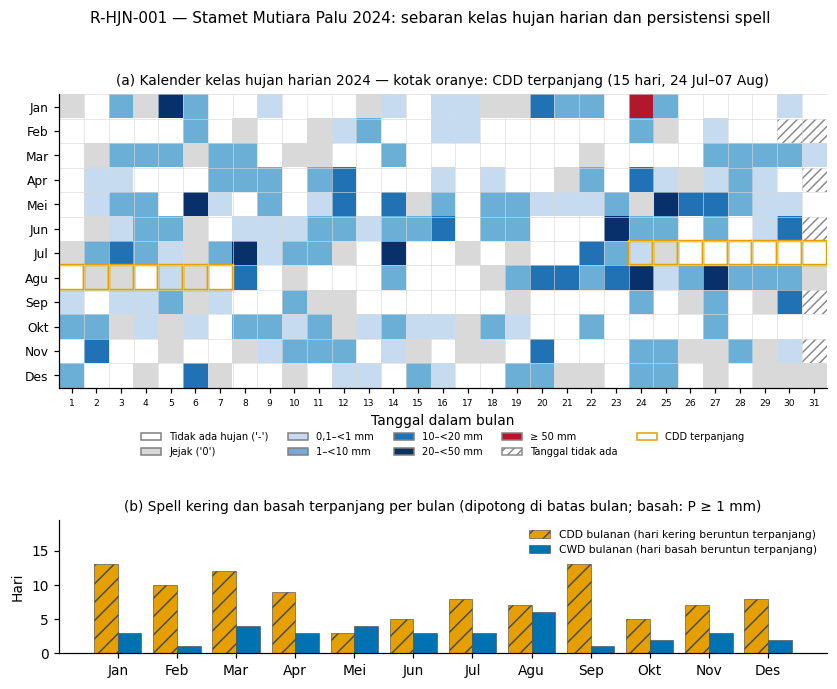

In [21]:
mrows = []
for m in range(1, 13):
    sub = obs[obs.month == m]; r_m = sub.rain_mm.to_numpy(float); w_m = r_m >= CONFIG["wet_day_mm"]
    s1, e1 = find_spells(~w_m); s2, e2 = find_spells(w_m)
    mrows.append({"bulan": ID_MON[m - 1], "total_mm": r_m.sum(), "hari_basah": int(w_m.sum()), "Rx1day_mm": r_m.max(),
                  "CDD_bulan": int((e1 - s1 + 1).max()) if len(s1) else 0, "CWD_bulan": int((e2 - s2 + 1).max()) if len(s2) else 0})
idx_m = pd.DataFrame(mrows); display(idx_m.round(1))
check("Bulanan: max CDD bulanan ≤ CDD tahunan", idx_m.CDD_bulan.max() <= idx["CDD_days"])
check("Bulanan: Σ total bulanan = total tahunan", abs(idx_m.total_mm.sum() - idx["annual_total_mm"]) < 1e-9)

# ---- figure: heatmap kalender kelas hujan + CDD/CWD bulanan ------------------------------------
def class_code(r):
    if not r.valid_date: return np.nan
    if r.raw_token == "-": return 0
    v = r.rain_mm
    return 1 if v == 0 else 2 if v < 1 else 3 if v < 10 else 4 if v < 20 else 5 if v < 50 else 6
M = np.full((12, 31), np.nan)
for r in tidy.itertuples(): M[r.month - 1, r.day - 1] = class_code(r)
pal = ["#ffffff", "#d9d9d9", "#c6dbef", "#6baed6", "#2171b5", "#08306b", "#b2182b"]
labels = ["Tidak ada hujan ('-')", "Jejak ('0')", "0,1–<1 mm", "1–<10 mm", "10–<20 mm", "20–<50 mm", "≥ 50 mm"]
fig = plt.figure(figsize=(9, 6.6)); gs = fig.add_gridspec(2, 1, height_ratios=[2.2, 1], hspace=0.62)
ax = fig.add_subplot(gs[0]); ax.imshow(M, cmap=ListedColormap(pal), vmin=-0.5, vmax=6.5, aspect="auto")
for mi in range(12):
    for di in range(31):
        if np.isnan(M[mi, di]): ax.add_patch(Rectangle((di - .5, mi - .5), 1, 1, fill=False, hatch="////", edgecolor="0.55", lw=0))
ax.set_xticks(range(31)); ax.set_xticklabels(range(1, 32), fontsize=6); ax.set_yticks(range(12)); ax.set_yticklabels(ID_MON, fontsize=8)
ax.set_xticks(np.arange(-.5, 31, 1), minor=True); ax.set_yticks(np.arange(-.5, 12, 1), minor=True); ax.grid(which="minor", color="0.85", lw=0.4); ax.tick_params(which="minor", length=0)
cdd_days = pd.date_range(idx["CDD_start"], idx["CDD_end"])
for d in cdd_days: ax.add_patch(Rectangle((d.day - 1.5, d.month - 1.5), 1, 1, fill=False, edgecolor="#E69F00", lw=1.6))
ax.set_xlabel("Tanggal dalam bulan"); ax.set_title(f"(a) Kalender kelas hujan harian {YEAR} — kotak oranye: CDD terpanjang ({idx['CDD_days']} hari, {idx['CDD_start']:%d %b}–{idx['CDD_end']:%d %b})", fontsize=9)
handles = [Patch(facecolor=c, edgecolor="0.5", label=l) for c, l in zip(pal, labels)] + [Patch(facecolor="white", edgecolor="0.55", hatch="////", label="Tanggal tidak ada"), Patch(facecolor="none", edgecolor="#E69F00", label="CDD terpanjang")]
ax.legend(handles=handles, ncol=5, fontsize=6.5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax2 = fig.add_subplot(gs[1]); xs = np.arange(12); w = 0.4
ax2.bar(xs - w/2, idx_m.CDD_bulan, w, color="#E69F00", hatch="//", edgecolor="0.3", linewidth=0.4, label="CDD bulanan (hari kering beruntun terpanjang)")
ax2.bar(xs + w/2, idx_m.CWD_bulan, w, color="#0072B2", edgecolor="0.3", linewidth=0.4, label="CWD bulanan (hari basah beruntun terpanjang)")
ax2.set_ylim(0, idx_m.CDD_bulan.max() * 1.5); ax2.set_xticks(xs); ax2.set_xticklabels(ID_MON); ax2.set_ylabel("Hari"); ax2.legend(frameon=False, fontsize=7, loc="upper right"); ax2.set_title("(b) Spell kering dan basah terpanjang per bulan (dipotong di batas bulan; basah: P ≥ 1 mm)", fontsize=9)
fig.suptitle("R-HJN-001 — Stamet Mutiara Palu 2024: sebaran kelas hujan harian dan persistensi spell", fontsize=10, y=0.995)
fig.savefig(OUT / "figures" / "r-hjn-001-spells.png", bbox_inches="tight"); fig.savefig(OUT / "figures" / "r-hjn-001-spells.pdf", bbox_inches="tight"); plt.show()

### Simpan artifact recipe (expected output contract + recipe card)

In [22]:
save_json(idx, OUT / "analysis" / "rain-indices.json")
dry_tbl.to_csv(OUT / "analysis" / "rain-spells-dry.csv", index=False); wet_tbl.to_csv(OUT / "analysis" / "rain-spells-wet.csv", index=False)
idx_m.to_csv(OUT / "analysis" / "rain-indices-monthly.csv", index=False); sens.to_csv(OUT / "analysis" / "rain-threshold-sensitivity.csv", index=False)

expected_contract = {
    "recipe_id": "R-HJN-001", "prompt_id": "P-HJN-001",
    "keys_required": ["PRCPTOT_mm", "R1mm_days", "R10mm_days", "R20mm_days", "R50mm_days", "SDII_mm_per_wet_day", "Rx1day_mm", "Rx5day_mm", "CDD_days", "CWD_days", "R95p_mm", "percentile_basis"],
    "invariants": ["Σ durasi spell = n_days", "Σ total spell basah = PRCPTOT", "PRCPTOT + Σ spell kering = total tahunan", "Rx1day = max stasiun"],
    "fixture": {"rain_mm": fx_rain.tolist(), "expected": expected},
    "actual_run": {k: (v.isoformat() if isinstance(v, pd.Timestamp) else v) for k, v in idx.items()},
}
save_json(expected_contract, OUT / "recipes" / "r-hjn-001-expected-output.json")

RECIPE_MD = f"""# Recipe R-HJN-001 — Indeks Hujan Ekstrem dan Spell Kering/Basah dengan Verifikasi terhadap Ringkasan Stasiun

**Prasyarat jalur praktik.** Komputasi lokal: LOKAL · PYTHON (numpy, pandas, matplotlib). AI bukan dependency eksekusi script.

**Problem.** Tabel harian stasiun (tanggal × bulan) memuat ringkasan bulanan, tetapi tidak menyatakan ekstrem, persistensi hari kering/basah, dan bukti bahwa hitungan turunannya benar.

**AI role.** AI menerjemahkan definisi ETCCDI menjadi fungsi, membuat dua implementasi independen (vektor dan brute-force), menyusun fixture hitung-tangan, dan melaporkan hasil verifikasi — tanpa menyimpulkan tren atau penyebab fisis.

**Recommended stack.** numpy, pandas, matplotlib.

**Prompt.** P-HJN-001 (file: p-hjn-001.md).

**Code.** fungsi `find_spells`, `find_spells_bruteforce`, `spell_table`, `compute_rain_indices` pada notebook `{CONFIG['notebook']}`.

**Expected output (contract).** rain-indices.json, rain-spells-dry.csv, rain-spells-wet.csv, rain-indices-monthly.csv, rain-threshold-sensitivity.csv, r-hjn-001-spells.png/pdf, r-hjn-001-expected-output.json.

**Check.** V1 pembanding stasiun · V2 partisi spell · V3 konservasi massa hujan · V4 vektor vs brute-force · V5 fixture hitung-tangan · V6 sensitivitas ambang/token.

**Executed (notebook ini, run `{CONFIG['run_id']}`).** Data Stamet Mutiara Palu {YEAR}: total {idx['annual_total_mm']:.1f} mm; PRCPTOT {idx['PRCPTOT_mm']:.1f} mm pada {idx['R1mm_days']} hari basah (SDII {idx['SDII_mm_per_wet_day']:.2f} mm/hari); Rx1day {idx['Rx1day_mm']:.1f} mm ({idx['Rx1day_date']:%d %b}); Rx5day {idx['Rx5day_mm']:.1f} mm ({idx['Rx5day_start']:%d}–{idx['Rx5day_end']:%d %b}); CDD {idx['CDD_days']} hari ({idx['CDD_start']:%d %b}–{idx['CDD_end']:%d %b}); CWD {idx['CWD_days']} hari; R95p {idx['R95p_mm']:.1f} mm ({100*idx['R95p_fraction_of_PRCPTOT']:.0f}% PRCPTOT, persentil within-year). Seluruh check V1–V6 lulus.

**Batas interpretasi.** Satu stasiun, satu tahun, tanpa klimatologi: tidak ada klaim tren, anomali klimatologis, ENSO/monsun, atau representasi spasial. R95p memakai persentil within-year. Makna token `-`/`0` disimpulkan dari kecocokan HH stasiun dan perlu konfirmasi ke stasiun.

**Related recipes.** R-QC-001 → R-ANA-001 → R-CAL-002/003 → R-VIS-001 → R-PUB-001.
"""
(OUT / "recipes" / "r-hjn-001.md").write_text(RECIPE_MD, encoding="utf-8")
show_md(RECIPE_MD)

# Recipe R-HJN-001 — Indeks Hujan Ekstrem dan Spell Kering/Basah dengan Verifikasi terhadap Ringkasan Stasiun

**Prasyarat jalur praktik.** Komputasi lokal: LOKAL · PYTHON (numpy, pandas, matplotlib). AI bukan dependency eksekusi script.

**Problem.** Tabel harian stasiun (tanggal × bulan) memuat ringkasan bulanan, tetapi tidak menyatakan ekstrem, persistensi hari kering/basah, dan bukti bahwa hitungan turunannya benar.

**AI role.** AI menerjemahkan definisi ETCCDI menjadi fungsi, membuat dua implementasi independen (vektor dan brute-force), menyusun fixture hitung-tangan, dan melaporkan hasil verifikasi — tanpa menyimpulkan tren atau penyebab fisis.

**Recommended stack.** numpy, pandas, matplotlib.

**Prompt.** P-HJN-001 (file: p-hjn-001.md).

**Code.** fungsi `find_spells`, `find_spells_bruteforce`, `spell_table`, `compute_rain_indices` pada notebook `cookbook_curah_hujan_palu_2024.ipynb`.

**Expected output (contract).** rain-indices.json, rain-spells-dry.csv, rain-spells-wet.csv, rain-indices-monthly.csv, rain-threshold-sensitivity.csv, r-hjn-001-spells.png/pdf, r-hjn-001-expected-output.json.

**Check.** V1 pembanding stasiun · V2 partisi spell · V3 konservasi massa hujan · V4 vektor vs brute-force · V5 fixture hitung-tangan · V6 sensitivitas ambang/token.

**Executed (notebook ini, run `HJN-PALU-2024-001`).** Data Stamet Mutiara Palu 2024: total 849.4 mm; PRCPTOT 829.0 mm pada 109 hari basah (SDII 7.61 mm/hari); Rx1day 50.5 mm (24 Jan); Rx5day 78.8 mm (20–24 Aug); CDD 15 hari (24 Jul–07 Aug); CWD 6 hari; R95p 221.2 mm (27% PRCPTOT, persentil within-year). Seluruh check V1–V6 lulus.

**Batas interpretasi.** Satu stasiun, satu tahun, tanpa klimatologi: tidak ada klaim tren, anomali klimatologis, ENSO/monsun, atau representasi spasial. R95p memakai persentil within-year. Makna token `-`/`0` disimpulkan dari kecocokan HH stasiun dan perlu konfirmasi ke stasiun.

**Related recipes.** R-QC-001 → R-ANA-001 → R-CAL-002/003 → R-VIS-001 → R-PUB-001.


## 14. R-PUB-001 / R-PUB-002 — Manifest, run record, dan caption

Setiap figure/tabel dihubungkan ke input, script, dan run ID. Hanya klaim yang dapat ditelusuri ke output yang ditulis di `summary.md`. Caption mengikuti aturan buku: sebut variabel, unit, sumber/run ID, kondisi penting, dan batas interpretasi.

In [23]:
captions = f"""# Caption draft (R-PUB-002) — run {CONFIG['run_id']}

**Figure R-HJN-001.** (a) Kalender kelas curah hujan harian (mm/hari) Stasiun Meteorologi Mutiara Palu, {YEAR}; kotak oranye menandai spell kering terpanjang ({idx['CDD_days']} hari berturut-turut dengan P < 1 mm). (b) Spell kering (CDD) dan basah (CWD) terpanjang per bulan, dipotong pada batas bulan. Sumber: file stasiun `{DATA_PATH.name}`; token `-` diperlakukan sebagai 0 mm. Satu stasiun, satu tahun; tidak menyatakan tren atau anomali klimatologis.

**Figure R-VIS-001.** Curah hujan harian (batang, mm/hari) dan akumulasi tahunan (garis, mm), {YEAR}. Segitiga hitam: token `0` (jejak/tak terukur). Label: tiga hari dengan hujan terbesar.

**Figure R-CS-002.** Debit hasil linear reservoir (mm/hari setara kedalaman DAS) untuk beberapa konstanta resesi k dengan forcing hujan Palu {YEAR}, ET = 0. Skenario ilustratif tanpa kalibrasi/validasi; bukan prakiraan banjir.
"""
(OUT / "figures" / "captions.md").write_text(captions, encoding="utf-8")

def git_commit():
    try: return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], stderr=subprocess.DEVNULL, text=True).strip()
    except Exception: return None

gen_by = {  # figure/tabel -> bagian notebook penghasil
    "figures/r-ana-001-monthly.png": "Bagian 7 (R-ANA-001)", "figures/r-cal-002-anomaly.png": "Bagian 8 (R-CAL-002)",
    "figures/r-cal-003-autocorr.png": "Bagian 9 (R-CAL-003)", "figures/r-vis-001-daily.png": "Bagian 10 (R-VIS-001)",
    "figures/r-cs-002-hydrograph.png": "Bagian 11 (R-CS-002)", "figures/r-hjn-001-spells.png": "Bagian 13 (R-HJN-001)"}
outputs = [p for p in sorted(OUT.rglob("*")) if p.is_file() and p.parent.name != "run-records" and p.name != "result-manifest.json"]
manifest = {
    "run_id": CONFIG["run_id"], "created_utc": datetime.now(timezone.utc).isoformat(), "git_commit": git_commit(),
    "command": f"jupyter nbconvert --to notebook --execute {CONFIG['notebook']}",
    "input": {"path": str(DATA_PATH), "sha256": sha256(DATA_PATH)},
    "parameters": {k: v for k, v in CONFIG.items() if k != "data_candidates"},
    "environment": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "matplotlib": matplotlib.__version__, "os": platform.platform()},
    "outputs": [{"path": str(p.relative_to(OUT)), "bytes": p.stat().st_size, "sha256": sha256(p), "generated_by": gen_by.get(str(p.relative_to(OUT)), CONFIG["notebook"])} for p in outputs],
}
save_json(manifest, OUT / "result-manifest.json")
(OUT / "summary.md").write_text(f"""# Ringkasan run {CONFIG['run_id']}
- Input: `{DATA_PATH.name}` (sha256 `{manifest['input']['sha256'][:12]}…`)
- Jumlah output: {len(outputs)} file; manifest: `result-manifest.json`
- Check lulus: {sum(c['passed'] for c in CHECKS)}/{len(CHECKS)}
- Klaim yang didukung: lihat bagian Ringkasan hasil di notebook; semua angka berasal dari output di atas.
""", encoding="utf-8")

run_record = {"run_id": CONFIG["run_id"], "exit_status": 0, "elapsed_s": round(time.time() - T0, 2), "checks_total": len(CHECKS),
              "checks_passed": sum(c["passed"] for c in CHECKS), "checks": CHECKS, "manifest_sha256": sha256(OUT / "result-manifest.json"), "status": "executed locally"}
save_json(run_record, OUT / "run-records" / "r-hjn-001.json")
print(f"Manifest: {len(outputs)} file | check lulus {run_record['checks_passed']}/{run_record['checks_total']} | waktu {run_record['elapsed_s']} s")
display(pd.DataFrame(manifest["outputs"])[["path", "bytes", "generated_by"]])

Manifest: 35 file | check lulus 51/51 | waktu 2.84 s


,path,bytes,generated_by
0,analysis/monthly-summary.csv,1006,cookbook_curah_hujan_palu_2024.ipynb
1,analysis/rain-indices-monthly.csv,347,cookbook_curah_hujan_palu_2024.ipynb
2,analysis/rain-indices.json,845,cookbook_curah_hujan_palu_2024.ipynb
3,analysis/rain-spells-dry.csv,2297,cookbook_curah_hujan_palu_2024.ipynb
4,analysis/rain-spells-wet.csv,2289,cookbook_curah_hujan_palu_2024.ipynb
5,analysis/rain-threshold-sensitivity.csv,268,cookbook_curah_hujan_palu_2024.ipynb
6,analysis/seasonal-summary.csv,397,cookbook_curah_hujan_palu_2024.ipynb
7,calc/autocorrelation-daily-rain.csv,752,cookbook_curah_hujan_palu_2024.ipynb
8,calc/monthly-anomaly-baseline.json,123,cookbook_curah_hujan_palu_2024.ipynb
9,calc/monthly-anomaly.csv,849,cookbook_curah_hujan_palu_2024.ipynb


## 15. Ringkasan hasil, batas interpretasi, dan langkah lanjut


### Temuan (semua angka berasal dari sel di atas)
- **Kualitas data:** 366 hari lengkap, tanpa gap, duplikat, nilai negatif, atau nilai di atas {CONFIG['physical_max_mm_day']:.0f} mm/hari. Baris ringkasan stasiun (JUMLAH, HH, max) cocok 12/12 bulan dengan hitungan ulang; token `-` diperlakukan 0 mm.
- **Total 2024:** {idx['annual_total_mm']:.1f} mm. Bulan terbasah **{wettest.bulan}** ({wettest.total_mm:.1f} mm), terkering **{driest.bulan}** ({driest.total_mm:.1f} mm). {n_low} dari 12 bulan masuk kelas *Rendah* (<100 mm/bulan).
- **Hari hujan:** {int(obs.raw_token.ne('-').sum())} hari menurut definisi stasiun (token ≠ `-`), tetapi hanya **{idx['R1mm_days']} hari** dengan P ≥ 1 mm.
- **Ekstrem:** Rx1day {idx['Rx1day_mm']:.1f} mm ({idx['Rx1day_date']:%d %b}); Rx5day {idx['Rx5day_mm']:.1f} mm ({idx['Rx5day_start']:%d}–{idx['Rx5day_end']:%d %b}); {idx['R20mm_days']} hari ≥ 20 mm; {idx['R50mm_days']} hari ≥ 50 mm.
- **Persistensi:** CDD {idx['CDD_days']} hari ({idx['CDD_start']:%d %b}–{idx['CDD_end']:%d %b}); CWD {idx['CWD_days']} hari; {idx['n_dry_spells_ge7d']} spell kering ≥ 7 hari. Autokorelasi harian lag-1 (Spearman) = {ac.r_spearman[1]:.2f}.
- **Model reservoir (ilustratif):** puncak debit {matrix.Q_puncak_mm_hari.min():.1f}–{matrix.Q_puncak_mm_hari.max():.1f} mm/hari tergantung k dan ET; neraca massa terjaga (residual maks {matrix.residual_neraca_mm.abs().max():.1e} mm).

### Batas interpretasi
- Satu stasiun, satu tahun: tidak ada klaim tren, perubahan iklim, atau representasi spasial Kota Palu.
- Anomali bulanan memakai baseline within-year, bukan normal klimatologi.
- Makna `-` dan `0` disimpulkan dari data (HH), belum dikonfirmasi stasiun; jam batas pengamatan tidak diketahui.
- Model reservoir: parameter, ET, dan luas DAS adalah skenario/asumsi; tanpa debit teramati tidak ada kalibrasi atau validasi.
- R95p memakai persentil within-year, tidak setara R95p klimatologis ETCCDI.
show_md(summary_md)